<a href="https://colab.research.google.com/github/Tulip0648/seismic-fault-impact/blob/main/module3/03_supervised_predictive_modelling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 3: Supervised Learning & Baseline Benchmarking

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tulip0648/seismic-fault-impact/blob/main/module3/03_supervised_predictive_modelling.ipynb)

**Course**: BITSF464 Machine Learning — Fall 2026  
**Project**: Seismological Fault Line Discovery & Earthquake Impact Profiling  

---

### Objectives
1. **Two-Stage Benchmarking**: Train and evaluate baseline machine learning algorithms on:
   - **Stage 1 (Base)**: Imputed & standardized physical coordinates and sensor metrics from Module 1.
   - **Stage 2 (Augmented)**: Base features coupled with tectonic fault distances and GMM posterior probabilities from Module 2.
2. **Team Roles**:
   - **Person 1**: Linear & Regularized Models (Logistic Regression with L1/L2/ElasticNet, Ridge/Lasso for MMI).
   - **Person 2**: Probabilistic & Discriminant Models (Gaussian Naive Bayes, LDA with shrinkage, QDA).
   - **Person 3 (Aaryan)**: Distance-Based & Margin Models ($k$-Nearest Neighbors, Support Vector Classifiers with probability calibration).
3. **Module 4 Handoff**: Generate cross-validated Out-of-Fold (OOF) prediction probabilities for the stacking meta-learner.


## 0. Environment Setup (Colab & Local)
Detects environment automatically. Sets data and artifact directories without requiring manual path changes.


In [1]:
import os
import sys

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("Running in Google Colab.")
    from google.colab import drive
    drive.mount('/content/drive')
    REPO_NAME = "seismic-fault-impact"
    REPO_PATH = f"/content/{REPO_NAME}"
    if not os.path.exists(REPO_PATH):
        !git clone https://github.com/Tulip0648/seismic-fault-impact.git {REPO_PATH}
    %cd {REPO_PATH}/module3
    !pip install -r ../requirements.txt -q
    DATA_BASE_DIR = "../data/processed"
    DATA_AUG_DIR = "../data/augmented"
    ARTIFACTS_DIR = "./artifacts"
    REPORTS_DIR = "./reports"
else:
    print("Running locally.")
    DATA_BASE_DIR = "../data/processed"
    DATA_AUG_DIR = "../data/augmented"
    ARTIFACTS_DIR = "./artifacts"
    REPORTS_DIR = "./reports"

os.makedirs(f"{ARTIFACTS_DIR}/models", exist_ok=True)
os.makedirs(f"{ARTIFACTS_DIR}/oof_predictions", exist_ok=True)
os.makedirs(f"{REPORTS_DIR}/figures", exist_ok=True)
print("Directories initialized successfully.")


Running locally.
Directories initialized successfully.


## 1. Imports & Global Configuration


In [2]:
import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
N_SPLITS = 5

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Global configuration loaded.")


Global configuration loaded.


## 2. Shared Data Ingestion & Target Preparation
Loads the exact same Base and Augmented datasets created by Module 1 and Module 2.  
Target mapping: `green`: 0, `yellow`: 1, `orange`: 2, `red`: 3.


In [3]:
# Target encoding mapping
ALERT_MAP = {'green': 0, 'yellow': 1, 'orange': 2, 'red': 3}
INV_ALERT_MAP = {v: k for k, v in ALERT_MAP.items()}

# 1. Load Base Splits (Module 1)
train_base = pd.read_parquet(os.path.join(DATA_BASE_DIR, "train_base.parquet"))
val_base = pd.read_parquet(os.path.join(DATA_BASE_DIR, "val_base.parquet"))
test_base = pd.read_parquet(os.path.join(DATA_BASE_DIR, "test_base.parquet"))

# 2. Load Augmented Splits (Module 2)
train_aug = pd.read_parquet(os.path.join(DATA_AUG_DIR, "train_augmented.parquet"))
val_aug = pd.read_parquet(os.path.join(DATA_AUG_DIR, "val_augmented.parquet"))
test_aug = pd.read_parquet(os.path.join(DATA_AUG_DIR, "test_augmented.parquet"))

# 3. Ensure target labels are encoded
for df in [train_base, val_base, test_base, train_aug, val_aug, test_aug]:
    if 'alert_label' not in df.columns and 'alert' in df.columns:
        df['alert_label'] = df['alert'].map(ALERT_MAP)

print(f"Train Base shape:      {train_base.shape}")
print(f"Train Augmented shape: {train_aug.shape}")
print(f"Test Base shape:       {test_base.shape}")
print(f"Test Augmented shape:  {test_aug.shape}")


Train Base shape:      (3105, 43)
Train Augmented shape: (3105, 68)
Test Base shape:       (666, 43)
Test Augmented shape:  (666, 68)


## 3. Feature Selection & Cross-Validation Setup
Defines the feature column subsets and initializes the shared 5-Fold Stratified Cross-Validation splitter.


In [4]:
# Excluded columns (metadata, raw categorical strings, and raw targets)
EXCLUDE_COLS = {'event_id', 'time', 'alert', 'alert_label', 'mmi', 'place', 'magType'}

# Base features: columns present in train_base minus excluded
BASE_FEATURES = [c for c in train_base.columns if c not in EXCLUDE_COLS]

# Augmented features: columns present in train_aug minus excluded
AUGMENTED_FEATURES = [c for c in train_aug.columns if c not in EXCLUDE_COLS]

print(f"Base feature count:       {len(BASE_FEATURES)}")
print(f"Augmented feature count:  {len(AUGMENTED_FEATURES)}")

# Shared Stratified K-Fold splitter
cv_splitter = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

def evaluate_predictions(y_true, y_pred, y_prob=None):
    """Calculates Macro F1, Weighted F1, and Multi-Class ROC-AUC (One-vs-Rest)."""
    metrics = {
        'macro_f1': f1_score(y_true, y_pred, average='macro'),
        'weighted_f1': f1_score(y_true, y_pred, average='weighted'),
    }
    if y_prob is not None:
        try:
            metrics['roc_auc_ovr'] = roc_auc_score(y_true, y_prob, multi_class='ovr', average='macro')
        except Exception:
            metrics['roc_auc_ovr'] = np.nan
    return metrics


Base feature count:       36
Augmented feature count:  61


---
## 4. Person 1: Linear & Regularized Models

**Owner**: Person 1  
**Algorithms**:
1. **Logistic Regression (Multi-Class PAGER `alert`)**: Tuned across L1 (Lasso), L2 (Ridge), and ElasticNet penalties with `class_weight='balanced'`.
2. **Ridge & Lasso Regression (Continuous ShakeMap `mmi`)**: Regularized linear regression comparing Base vs. Augmented feature sets.
3. **Interpretability & Significance**: Coefficient inspection and permutation importance analysis on tectonic fault features (`dist_to_nearest_fault_km`, `gmm_prob_*`).

---

### 4.0 Data Alignment Verification & Helper Setup
Before fitting any models, we verify that row indices and `event_id` values match identically between the Module 1 (**Base**) and Module 2 (**Augmented**) partitions, inspect target distributions (`alert_label` and continuous `mmi`), and initialize evaluation helpers (including Log Loss and inference latency for downstream Module 4 leaderboard compatibility).

In [5]:
# Person 1 (Setup): Imports, Alignment Verification & Evaluation Helpers
import time
from sklearn.linear_model import LogisticRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (
    log_loss,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    roc_curve,
    auc
)
from sklearn.inspection import permutation_importance

# 1. Verify identical row ordering & event_id alignment between Base and Augmented splits
assert len(train_base) == len(train_aug), "Train Base and Augmented row counts differ!"
assert len(test_base) == len(test_aug), "Test Base and Augmented row counts differ!"
assert (train_base['event_id'].values == train_aug['event_id'].values).all(), "Train event_id mismatch!"
assert (test_base['event_id'].values == test_aug['event_id'].values).all(), "Test event_id mismatch!"
assert (train_base['alert_label'].values == train_aug['alert_label'].values).all(), "Train alert_label mismatch!"
assert (test_base['alert_label'].values == test_aug['alert_label'].values).all(), "Test alert_label mismatch!"
print("✓ Alignment check passed: Base and Augmented splits have identical event_id & label ordering.")

# 2. Extract feature matrices and targets (scoped with _p1 to avoid overwriting other sections)
X_base_p1 = train_base[BASE_FEATURES].copy()
X_aug_p1 = train_aug[AUGMENTED_FEATURES].copy()
y_alert_p1 = train_base['alert_label'].values.astype(int)

X_test_base_p1 = test_base[BASE_FEATURES].copy()
X_test_aug_p1 = test_aug[AUGMENTED_FEATURES].copy()
y_test_alert_p1 = test_base['alert_label'].values.astype(int)

# Continuous MMI targets for Ridge & Lasso regression
y_mmi_train_p1 = train_base['mmi'].values.astype(float)
y_mmi_test_p1 = test_base['mmi'].values.astype(float)

# Verify no NaNs in features or targets
assert X_base_p1.isna().sum().sum() == 0, "NaNs detected in X_base_p1!"
assert X_aug_p1.isna().sum().sum() == 0, "NaNs detected in X_aug_p1!"
assert not np.isnan(y_mmi_train_p1).any(), "NaNs detected in y_mmi_train_p1!"
assert not np.isnan(y_mmi_test_p1).any(), "NaNs detected in y_mmi_test_p1!"
print("✓ Zero-NaN check passed for Base features, Augmented features, and continuous MMI targets.")

# 3. Inspect target summaries
alert_counts = pd.Series(y_alert_p1).map(INV_ALERT_MAP).value_counts().reindex(['green', 'yellow', 'orange', 'red'])
print("\nTraining PAGER Alert Class Distribution:")
for cls_name, cnt in alert_counts.items():
    print(f"  {cls_name:6s}: {cnt:4d} ({cnt / len(y_alert_p1) * 100:5.2f}%)")

print(f"\nTraining MMI Summary: mean={y_mmi_train_p1.mean():.3f}, std={y_mmi_train_p1.std():.3f}, "
      f"min={y_mmi_train_p1.min():.2f}, max={y_mmi_train_p1.max():.2f}")
print(f"Base feature count: {X_base_p1.shape[1]} | Augmented feature count: {X_aug_p1.shape[1]}")

# 4. Identify Module 2 newly added tectonic features for downstream interpretability analysis
NEW_FAULT_FEATURES = [c for c in AUGMENTED_FEATURES if c not in BASE_FEATURES]
print(f"New Module 2 fault features ({len(NEW_FAULT_FEATURES)}): {NEW_FAULT_FEATURES[:6]} ...")

# 5. Person 1 evaluation helpers
def evaluate_p1_classification(y_true, y_pred, y_prob):
    """Wraps shared evaluate_predictions and adds multi-class Log Loss for Module 4 compatibility."""
    scores = evaluate_predictions(y_true, y_pred, y_prob)
    scores['log_loss'] = log_loss(y_true, y_prob, labels=list(range(len(ALERT_MAP))))
    return scores

def evaluate_p1_regression(y_true, y_pred):
    """Computes RMSE, MAE, and R^2 for continuous MMI prediction."""
    return {
        'rmse': float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'mae': float(mean_absolute_error(y_true, y_pred)),
        'r2': float(r2_score(y_true, y_pred))
    }

def measure_inference_latency_ms(fitted_model, X_sample, n_runs=20):
    """Measures average full-batch and per-sample inference latency in milliseconds."""
    start = time.perf_counter()
    for _ in range(n_runs):
        _ = fitted_model.predict_proba(X_sample)
    elapsed_ms = (time.perf_counter() - start) * 1000.0 / n_runs
    return elapsed_ms, elapsed_ms / len(X_sample)

✓ Alignment check passed: Base and Augmented splits have identical event_id & label ordering.
✓ Zero-NaN check passed for Base features, Augmented features, and continuous MMI targets.

Training PAGER Alert Class Distribution:
  green : 2823 (90.92%)
  yellow:  201 ( 6.47%)
  orange:   59 ( 1.90%)
  red   :   22 ( 0.71%)

Training MMI Summary: mean=3.645, std=2.239, min=0.00, max=9.54
Base feature count: 36 | Augmented feature count: 61
New Module 2 fault features (25): ['dbscan_cluster', 'is_background_noise', 'dist_to_nearest_fault_km', 'gmm_cluster', 'gmm_log_likelihood', 'gmm_prob_0'] ...


### 4.1 Logistic Regression — Stage 1 (Base Features)
Implement and tune multi-class Logistic Regression on `BASE_FEATURES` using the shared 5-fold stratified cross-validation split (`cv_splitter`):
- **Regularization Penalties**: Compare **L2 (Ridge)**, **L1 (Lasso)**, and **ElasticNet** ($l_1$-ratio $\in \{0.25, 0.50, 0.75\}$).
- **Solvers & Strength**: Tune regularization strength $C \in \{0.01, 0.1, 1.0, 10.0, 100.0\}$ across `lbfgs` and `saga`.
- **Class Imbalance**: Apply `class_weight='balanced'` to upweight rare `orange` and `red` alert events.
- **Metrics**: Log 5-fold CV **Macro F1** (primary selection criterion), **Weighted F1**, **Multi-class ROC-AUC (OvR)**, and **Log Loss**.

In [6]:
# Person 1 (Model 1 — Stage 1): Logistic Regression on Base Features (Parallelized, max_iter=3000)
import warnings
from joblib import Parallel, delayed
from sklearn.exceptions import ConvergenceWarning

# Shared hyperparameter search space (reused identically for Stage 2 Augmented)
LR_PARAM_GRID = []

# 1. L2 (Ridge) with lbfgs and saga
for c_val in [0.01, 0.1, 1.0, 10.0, 100.0]:
    LR_PARAM_GRID.append({'penalty': 'l2', 'solver': 'lbfgs', 'C': c_val, 'l1_ratio': None})
for c_val in [0.1, 1.0, 10.0]:
    LR_PARAM_GRID.append({'penalty': 'l2', 'solver': 'saga', 'C': c_val, 'l1_ratio': None})

# 2. L1 (Lasso) with saga
for c_val in [0.01, 0.1, 1.0, 10.0]:
    LR_PARAM_GRID.append({'penalty': 'l1', 'solver': 'saga', 'C': c_val, 'l1_ratio': None})

# 3. ElasticNet with saga
for c_val in [0.1, 1.0, 10.0]:
    for l1_r in [0.25, 0.5, 0.75]:
        LR_PARAM_GRID.append({'penalty': 'elasticnet', 'solver': 'saga', 'C': c_val, 'l1_ratio': l1_r})


def build_lr_pipeline(params, random_state=RANDOM_STATE):
    """Constructs a leakage-free StandardScaler + LogisticRegression pipeline (full max_iter=3000)."""
    lr_kwargs = {
        'penalty': params['penalty'],
        'solver': params['solver'],
        'C': float(params['C']),
        'class_weight': 'balanced',
        'max_iter': 3000 if params['solver'] == 'saga' else 2000,
        'tol': 1e-3 if params['solver'] == 'saga' else 1e-4,
        'random_state': random_state,
    }
    if params['penalty'] == 'elasticnet':
        lr_kwargs['l1_ratio'] = float(params['l1_ratio'])

    return Pipeline([
        ('scaler', StandardScaler()),
        ('lr', LogisticRegression(**lr_kwargs))
    ])


def _fit_one_lr_fold(X_tr, y_tr, X_va, va_idx, params, random_state):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        warnings.simplefilter("ignore", FutureWarning)
        pipe = build_lr_pipeline(params, random_state=random_state)
        pipe.fit(X_tr, y_tr)
        y_pred = pipe.predict(X_va)
        y_prob = pipe.predict_proba(X_va)
    return va_idx, y_pred, y_prob


def run_lr_cv_sweep(X_df, y_arr, param_grid, stage_label="Base"):
    """Runs parallelized 5-fold Stratified CV across all LR configs with live progress."""
    results = []
    n_classes = len(ALERT_MAP)
    splits = list(cv_splitter.split(X_df, y_arr))
    total_start = time.perf_counter()

    for idx, params in enumerate(param_grid, start=1):
        t0 = time.perf_counter()
        fold_outputs = Parallel(n_jobs=-1)(
            delayed(_fit_one_lr_fold)(
                X_df.iloc[tr_idx], y_arr[tr_idx], X_df.iloc[va_idx], va_idx, params, RANDOM_STATE
            )
            for tr_idx, va_idx in splits
        )

        oof_probs = np.zeros((len(y_arr), n_classes), dtype=np.float64)
        oof_preds = np.zeros(len(y_arr), dtype=int)
        fold_macro_f1, fold_weighted_f1, fold_roc, fold_ll = [], [], [], []

        for va_idx, y_pred, y_prob in fold_outputs:
            oof_preds[va_idx] = y_pred
            oof_probs[va_idx] = y_prob
            scores = evaluate_p1_classification(y_arr[va_idx], y_pred, y_prob)
            fold_macro_f1.append(scores['macro_f1'])
            fold_weighted_f1.append(scores['weighted_f1'])
            fold_roc.append(scores['roc_auc_ovr'])
            fold_ll.append(scores['log_loss'])

        mean_f1 = float(np.mean(fold_macro_f1))
        mean_roc = float(np.mean(fold_roc))
        dt = time.perf_counter() - t0
        l1_str = f" l1={params['l1_ratio']}" if params['l1_ratio'] is not None else ""
        print(f"[{idx:2d}/{len(param_grid)}] {params['penalty']:10s} | {params['solver']:5s} | "
              f"C={params['C']:<5g}{l1_str:8s} -> Macro F1={mean_f1:.4f}, ROC-AUC={mean_roc:.4f} ({dt:.1f}s)")

        results.append({
            'penalty': params['penalty'],
            'solver': params['solver'],
            'C': params['C'],
            'l1_ratio': params['l1_ratio'],
            'mean_macro_f1': mean_f1,
            'std_macro_f1': float(np.std(fold_macro_f1)),
            'mean_weighted_f1': float(np.mean(fold_weighted_f1)),
            'mean_roc_auc': mean_roc,
            'mean_log_loss': float(np.mean(fold_ll)),
            '_fold_macro_f1': fold_macro_f1,
            '_oof_preds': oof_preds,
            '_oof_probs': oof_probs,
        })

    print(f"\nCompleted {stage_label} sweep in {time.perf_counter() - total_start:.1f}s.\n")

    df_res = pd.DataFrame(results).sort_values(
        by=['mean_macro_f1', 'mean_roc_auc'], ascending=False
    ).reset_index(drop=True)

    best_row = df_res.iloc[0]
    best_params = {
        'penalty': best_row['penalty'],
        'solver': best_row['solver'],
        'C': float(best_row['C']),
        'l1_ratio': None if pd.isna(best_row['l1_ratio']) else float(best_row['l1_ratio']),
    }
    best_oof = {
        'preds': best_row['_oof_preds'],
        'probs': best_row['_oof_probs'],
        'fold_macro_f1': best_row['_fold_macro_f1'],
    }

    display_cols = ['penalty', 'solver', 'C', 'l1_ratio', 'mean_macro_f1', 'std_macro_f1',
                    'mean_weighted_f1', 'mean_roc_auc', 'mean_log_loss']
    df_display = df_res[display_cols].copy()

    print(f"=== Logistic Regression ({stage_label} Features) — Top 8 Configurations ===")
    print(df_display.head(8).round(4).to_string(index=False))

    print(f"\n=== Best Config per Penalty Family ({stage_label}) ===")
    best_by_penalty = df_display.groupby('penalty', as_index=False).first()
    print(best_by_penalty.round(4).to_string(index=False))

    print(f"\nBest {stage_label} LR Config: {best_params}")
    print(f"  Macro F1:    {best_row['mean_macro_f1']:.4f} ± {best_row['std_macro_f1']:.4f}")
    print(f"  Weighted F1: {best_row['mean_weighted_f1']:.4f}")
    print(f"  ROC-AUC OvR: {best_row['mean_roc_auc']:.4f}")
    print(f"  Log Loss:    {best_row['mean_log_loss']:.4f}")

    return df_display, best_params, best_oof


# Run Stage 1 (Base Features) sweep
df_lr_base, best_lr_base_params, oof_lr_base = run_lr_cv_sweep(
    X_base_p1, y_alert_p1, LR_PARAM_GRID, stage_label="Base"
)

# Verify OOF probability sanity & measure inference latency on test_base
assert np.allclose(oof_lr_base['probs'].sum(axis=1), 1.0), "Base LR OOF probabilities do not sum to 1.0!"

lr_base_full_pipe = build_lr_pipeline(best_lr_base_params)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    warnings.simplefilter("ignore", FutureWarning)
    lr_base_full_pipe.fit(X_base_p1, y_alert_p1)

lr_base_batch_ms, lr_base_sample_ms = measure_inference_latency_ms(lr_base_full_pipe, X_test_base_p1)
print(f"\nBase LR Test Inference Latency: {lr_base_batch_ms:.2f} ms / batch ({lr_base_sample_ms:.4f} ms / sample)")

[ 1/21] l2         | lbfgs | C=0.01          -> Macro F1=0.3229, ROC-AUC=0.8108 (2.5s)


[ 2/21] l2         | lbfgs | C=0.1           -> Macro F1=0.3309, ROC-AUC=0.8150 (1.6s)


[ 3/21] l2         | lbfgs | C=1             -> Macro F1=0.3404, ROC-AUC=0.8146 (1.7s)


[ 4/21] l2         | lbfgs | C=10            -> Macro F1=0.3456, ROC-AUC=0.8179 (1.8s)


[ 5/21] l2         | lbfgs | C=100           -> Macro F1=0.3446, ROC-AUC=0.8162 (1.9s)


[ 6/21] l2         | saga  | C=0.1           -> Macro F1=0.3265, ROC-AUC=0.7906 (5.0s)


... (12 outputs left out)

[19/21] elasticnet | saga  | C=10    l1=0.25 -> Macro F1=0.3421, ROC-AUC=0.7906 (9.6s)


[20/21] elasticnet | saga  | C=10    l1=0.5  -> Macro F1=0.3392, ROC-AUC=0.7925 (9.9s)


[21/21] elasticnet | saga  | C=10    l1=0.75 -> Macro F1=0.3392, ROC-AUC=0.7900 (9.5s)

Completed Base sweep in 146.9s.

=== Logistic Regression (Base Features) — Top 8 Configurations ===
   penalty solver     C  l1_ratio  mean_macro_f1  std_macro_f1  mean_weighted_f1  mean_roc_auc  mean_log_loss
        l2  lbfgs  10.0       NaN         0.3456        0.0338            0.8181        0.8179         0.6838
        l2  lbfgs 100.0       NaN         0.3446        0.0301            0.8179        0.8162         0.7317
elasticnet   saga  10.0      0.25         0.3421        0.0398            0.8209        0.7906         0.7636
        l2  lbfgs   1.0       NaN         0.3404        0.0308            0.8194        0.8146         0.6856
elasticnet   saga  10.0      0.50         0.3392        0.0392            0.8154        0.7925         0.7530
elasticnet   saga  10.0      0.75         0.3392        0.0395            0.8177        0.7900         0.7690
        l1   saga   1.0       NaN         


Base LR Test Inference Latency: 0.95 ms / batch (0.0014 ms / sample)


### 4.2 Logistic Regression — Stage 2 (Augmented Features)
Train and tune the exact same Logistic Regression hyperparameter grid (L1, L2, ElasticNet across `lbfgs` and `saga` with `class_weight='balanced'`) on `AUGMENTED_FEATURES` (Base + PCA + DBSCAN fault distances + GMM EM posteriors) using the identical 5-fold CV splits, then quantify the Stage 2 vs. Stage 1 performance deltas ($\Delta$).

In [7]:
# Person 1 (Model 1 — Stage 2): Logistic Regression on Augmented Features
df_lr_aug, best_lr_aug_params, oof_lr_aug = run_lr_cv_sweep(
    X_aug_p1, y_alert_p1, LR_PARAM_GRID, stage_label="Augmented"
)

# Verify OOF probability sanity
assert np.allclose(oof_lr_aug['probs'].sum(axis=1), 1.0), "Augmented LR OOF probabilities do not sum to 1.0!"

# Fit best Augmented LR pipeline on full training set & measure inference latency
lr_aug_full_pipe = build_lr_pipeline(best_lr_aug_params)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    warnings.simplefilter("ignore", FutureWarning)
    lr_aug_full_pipe.fit(X_aug_p1, y_alert_p1)

lr_aug_batch_ms, lr_aug_sample_ms = measure_inference_latency_ms(lr_aug_full_pipe, X_test_aug_p1)
print(f"\nAugmented LR Test Inference Latency: {lr_aug_batch_ms:.2f} ms / batch ({lr_aug_sample_ms:.4f} ms / sample)")

# Quick Stage 2 vs Stage 1 Delta Check
base_best = df_lr_base.iloc[0]
aug_best = df_lr_aug.iloc[0]

delta_lr_macro_f1 = aug_best['mean_macro_f1'] - base_best['mean_macro_f1']
delta_lr_weighted_f1 = aug_best['mean_weighted_f1'] - base_best['mean_weighted_f1']
delta_lr_roc_auc = aug_best['mean_roc_auc'] - base_best['mean_roc_auc']
delta_lr_log_loss = aug_best['mean_log_loss'] - base_best['mean_log_loss']

print("\n=== Logistic Regression: Stage 2 (Augmented) vs Stage 1 (Base) Deltas ===")
print(f"  Δ Macro F1:    {delta_lr_macro_f1:+.4f}  ({base_best['mean_macro_f1']:.4f} -> {aug_best['mean_macro_f1']:.4f})")
print(f"  Δ Weighted F1: {delta_lr_weighted_f1:+.4f}  ({base_best['mean_weighted_f1']:.4f} -> {aug_best['mean_weighted_f1']:.4f})")
print(f"  Δ ROC-AUC OvR: {delta_lr_roc_auc:+.4f}  ({base_best['mean_roc_auc']:.4f} -> {aug_best['mean_roc_auc']:.4f})")
print(f"  Δ Log Loss:    {delta_lr_log_loss:+.4f}  ({base_best['mean_log_loss']:.4f} -> {aug_best['mean_log_loss']:.4f})")

[ 1/21] l2         | lbfgs | C=0.01          -> Macro F1=0.3257, ROC-AUC=0.8074 (0.1s)


[ 2/21] l2         | lbfgs | C=0.1           -> Macro F1=0.3308, ROC-AUC=0.8031 (0.1s)


[ 3/21] l2         | lbfgs | C=1             -> Macro F1=0.3366, ROC-AUC=0.7853 (0.2s)


[ 4/21] l2         | lbfgs | C=10            -> Macro F1=0.3407, ROC-AUC=0.7744 (0.4s)


[ 5/21] l2         | lbfgs | C=100           -> Macro F1=0.3301, ROC-AUC=0.7701 (0.7s)


[ 6/21] l2         | saga  | C=0.1           -> Macro F1=0.3161, ROC-AUC=0.7645 (8.1s)


... (12 outputs left out)

[19/21] elasticnet | saga  | C=10    l1=0.25 -> Macro F1=0.3368, ROC-AUC=0.7608 (17.7s)


[20/21] elasticnet | saga  | C=10    l1=0.5  -> Macro F1=0.3299, ROC-AUC=0.7577 (17.2s)


[21/21] elasticnet | saga  | C=10    l1=0.75 -> Macro F1=0.3318, ROC-AUC=0.7643 (17.4s)

Completed Augmented sweep in 236.3s.

=== Logistic Regression (Augmented Features) — Top 8 Configurations ===
   penalty solver     C  l1_ratio  mean_macro_f1  std_macro_f1  mean_weighted_f1  mean_roc_auc  mean_log_loss
        l2  lbfgs  10.0       NaN         0.3407        0.0441            0.8217        0.7744         0.7851
elasticnet   saga  10.0      0.25         0.3368        0.0432            0.8227        0.7608         0.8562
        l2  lbfgs   1.0       NaN         0.3366        0.0387            0.8238        0.7853         0.7205
        l1   saga  10.0       NaN         0.3334        0.0351            0.8179        0.7561         0.9016
elasticnet   saga  10.0      0.75         0.3318        0.0446            0.8178        0.7643         0.8676
        l2  lbfgs   0.1       NaN         0.3308        0.0167            0.8227        0.8031         0.6449
        l2  lbfgs 100.0       N


Augmented LR Test Inference Latency: 1.10 ms / batch (0.0017 ms / sample)

=== Logistic Regression: Stage 2 (Augmented) vs Stage 1 (Base) Deltas ===
  Δ Macro F1:    -0.0049  (0.3456 -> 0.3407)
  Δ Weighted F1: +0.0036  (0.8181 -> 0.8217)
  Δ ROC-AUC OvR: -0.0436  (0.8179 -> 0.7744)
  Δ Log Loss:    +0.1013  (0.6838 -> 0.7851)


### 4.3 Ridge & Lasso Regression — Continuous ShakeMap `mmi` Prediction (Base vs. Augmented)
Evaluate regularized linear regression models (**Ridge / L2** and **Lasso / L1**) for predicting continuous ground shaking intensity (`mmi`) under the exact same 5-fold Stratified CV splits (stratified on `alert_label` so fold partitions match classification identically):
- **Stage 1 (Base Features)** vs. **Stage 2 (Augmented Features)** across log-spaced regularization strengths ($\alpha$).
- **Metrics**: 5-fold CV **RMSE** (primary selection criterion), **MAE**, and **$R^2$**, plus holdout test-set scores and Stage 2 − Stage 1 deltas ($\Delta$).
- **Sparsity Audit**: Count how many Base vs. Module 2 fault features survive Lasso's L1 feature selection.

In [8]:
# Person 1 (Model 2): Ridge & Lasso Regression for Continuous MMI (Base vs. Augmented)
RIDGE_ALPHAS = np.logspace(-3, 3, 13)   # 0.001 to 1000
LASSO_ALPHAS = np.logspace(-4, 1, 11)   # 0.0001 to 10

# Reuse the exact same 5-fold splits (stratified on alert_label)
mmi_cv_splits = list(cv_splitter.split(X_base_p1, y_alert_p1))


def build_reg_pipeline(model_type, alpha):
    if model_type == 'Ridge':
        reg = Ridge(alpha=float(alpha), random_state=RANDOM_STATE)
    elif model_type == 'Lasso':
        reg = Lasso(alpha=float(alpha), max_iter=10000, tol=1e-4, random_state=RANDOM_STATE)
    else:
        raise ValueError(f"Unsupported model_type: {model_type}")
    return Pipeline([('scaler', StandardScaler()), ('reg', reg)])


def run_mmi_cv_sweep(X_df, y_mmi, model_type, alphas, stage_label="Base"):
    """Sweeps alpha via 5-fold CV for Ridge or Lasso on continuous MMI."""
    rows = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)

        for alpha in alphas:
            fold_rmse, fold_mae, fold_r2 = [], [], []
            oof_preds = np.zeros(len(y_mmi), dtype=np.float64)

            for tr_idx, va_idx in mmi_cv_splits:
                pipe = build_reg_pipeline(model_type, alpha)
                pipe.fit(X_df.iloc[tr_idx], y_mmi[tr_idx])
                y_hat = pipe.predict(X_df.iloc[va_idx])
                oof_preds[va_idx] = y_hat

                sc = evaluate_p1_regression(y_mmi[va_idx], y_hat)
                fold_rmse.append(sc['rmse'])
                fold_mae.append(sc['mae'])
                fold_r2.append(sc['r2'])

            rows.append({
                'model': model_type,
                'stage': stage_label,
                'alpha': float(alpha),
                'mean_rmse': float(np.mean(fold_rmse)),
                'std_rmse': float(np.std(fold_rmse)),
                'mean_mae': float(np.mean(fold_mae)),
                'mean_r2': float(np.mean(fold_r2)),
                '_oof_preds': oof_preds,
            })

    df_res = pd.DataFrame(rows).sort_values(by='mean_rmse', ascending=True).reset_index(drop=True)
    best_row = df_res.iloc[0]
    best_alpha = float(best_row['alpha'])
    best_oof = best_row['_oof_preds']

    # Fit best model on full training set to record holdout test metrics & coefficients
    full_pipe = build_reg_pipeline(model_type, best_alpha)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        full_pipe.fit(X_df, y_mmi)

    display_cols = ['model', 'stage', 'alpha', 'mean_rmse', 'std_rmse', 'mean_mae', 'mean_r2']
    return df_res[display_cols].copy(), best_alpha, best_oof, full_pipe


# 1. Run Ridge & Lasso sweeps on Base and Augmented feature sets
df_ridge_base, best_ridge_base_alpha, oof_ridge_base, ridge_base_full_pipe = run_mmi_cv_sweep(
    X_base_p1, y_mmi_train_p1, 'Ridge', RIDGE_ALPHAS, stage_label='Base'
)
df_ridge_aug, best_ridge_aug_alpha, oof_ridge_aug, ridge_aug_full_pipe = run_mmi_cv_sweep(
    X_aug_p1, y_mmi_train_p1, 'Ridge', RIDGE_ALPHAS, stage_label='Augmented'
)
df_lasso_base, best_lasso_base_alpha, oof_lasso_base, lasso_base_full_pipe = run_mmi_cv_sweep(
    X_base_p1, y_mmi_train_p1, 'Lasso', LASSO_ALPHAS, stage_label='Base'
)
df_lasso_aug, best_lasso_aug_alpha, oof_lasso_aug, lasso_aug_full_pipe = run_mmi_cv_sweep(
    X_aug_p1, y_mmi_train_p1, 'Lasso', LASSO_ALPHAS, stage_label='Augmented'
)

# 2. Evaluate best full-fit models on holdout test split
test_scores_mmi = {
    ('Ridge', 'Base'):      evaluate_p1_regression(y_mmi_test_p1, ridge_base_full_pipe.predict(X_test_base_p1)),
    ('Ridge', 'Augmented'): evaluate_p1_regression(y_mmi_test_p1, ridge_aug_full_pipe.predict(X_test_aug_p1)),
    ('Lasso', 'Base'):      evaluate_p1_regression(y_mmi_test_p1, lasso_base_full_pipe.predict(X_test_base_p1)),
    ('Lasso', 'Augmented'): evaluate_p1_regression(y_mmi_test_p1, lasso_aug_full_pipe.predict(X_test_aug_p1)),
}

# 3. Compile consolidated MMI regression summary table
mmi_summary_rows = []
for df_m, m_name, stg in [
    (df_ridge_base, 'Ridge', 'Base'),
    (df_ridge_aug,  'Ridge', 'Augmented'),
    (df_lasso_base, 'Lasso', 'Base'),
    (df_lasso_aug,  'Lasso', 'Augmented'),
]:
    top = df_m.iloc[0]
    tst = test_scores_mmi[(m_name, stg)]
    mmi_summary_rows.append({
        'Model': m_name,
        'Feature Set': stg,
        'Best Alpha': top['alpha'],
        'CV RMSE': top['mean_rmse'],
        'CV RMSE Std': top['std_rmse'],
        'CV MAE': top['mean_mae'],
        'CV R2': top['mean_r2'],
        'Test RMSE': tst['rmse'],
        'Test R2': tst['r2'],
    })

df_mmi_summary = pd.DataFrame(mmi_summary_rows)
print("=== Continuous MMI Prediction: Ridge & Lasso (Base vs. Augmented) ===")
print(df_mmi_summary.round(4).to_string(index=False))

# 4. Compute Stage 2 vs Stage 1 deltas for Ridge and Lasso
print("\n=== MMI Regression Deltas (Augmented - Base) ===")
for m_name in ['Ridge', 'Lasso']:
    r_base = df_mmi_summary[(df_mmi_summary['Model'] == m_name) & (df_mmi_summary['Feature Set'] == 'Base')].iloc[0]
    r_aug  = df_mmi_summary[(df_mmi_summary['Model'] == m_name) & (df_mmi_summary['Feature Set'] == 'Augmented')].iloc[0]
    print(f"  {m_name:5s} | Δ CV RMSE: {r_aug['CV RMSE'] - r_base['CV RMSE']:+.4f} "
          f"| Δ CV MAE: {r_aug['CV MAE'] - r_base['CV MAE']:+.4f} "
          f"| Δ CV R²: {r_aug['CV R2'] - r_base['CV R2']:+.4f} "
          f"| Δ Test R²: {r_aug['Test R2'] - r_base['Test R2']:+.4f}")

# 5. Lasso Sparsity Audit on Augmented Features
lasso_aug_coefs = pd.Series(lasso_aug_full_pipe.named_steps['reg'].coef_, index=AUGMENTED_FEATURES)
nonzero_all = lasso_aug_coefs[lasso_aug_coefs.abs() > 1e-6]
nonzero_fault = nonzero_all[nonzero_all.index.isin(NEW_FAULT_FEATURES)]

print(f"\n=== Lasso (Augmented, alpha={best_lasso_aug_alpha:g}) Sparsity Audit ===")
print(f"  Non-zero features retained: {len(nonzero_all)} / {len(AUGMENTED_FEATURES)}")
print(f"  Module 2 fault features retained: {len(nonzero_fault)} / {len(NEW_FAULT_FEATURES)}")
if len(nonzero_fault) > 0:
    print("  Top retained Module 2 fault features (standardized weight):")
    for feat, w in nonzero_fault.reindex(nonzero_fault.abs().sort_values(ascending=False).index).head(8).items():
        print(f"    {feat:28s}: {w:+.4f}")

=== Continuous MMI Prediction: Ridge & Lasso (Base vs. Augmented) ===
Model Feature Set  Best Alpha  CV RMSE  CV RMSE Std  CV MAE  CV R2  Test RMSE  Test R2
Ridge        Base      0.1000   1.6306       0.0465  1.2466 0.4687     1.6471   0.4688
Ridge   Augmented      0.3162   1.4674       0.0251  1.0851 0.5698     1.4902   0.5652
Lasso        Base      0.0003   1.6305       0.0466  1.2466 0.4687     1.6465   0.4691
Lasso   Augmented      0.0100   1.4667       0.0296  1.0818 0.5702     1.4925   0.5638

=== MMI Regression Deltas (Augmented - Base) ===
  Ridge | Δ CV RMSE: -0.1631 | Δ CV MAE: -0.1616 | Δ CV R²: +0.1011 | Δ Test R²: +0.0964
  Lasso | Δ CV RMSE: -0.1638 | Δ CV MAE: -0.1648 | Δ CV R²: +0.1015 | Δ Test R²: +0.0947

=== Lasso (Augmented, alpha=0.01) Sparsity Audit ===
  Non-zero features retained: 41 / 61
  Module 2 fault features retained: 17 / 25
  Top retained Module 2 fault features (standardized weight):
    gmm_prob_15                 : -0.5065
    gmm_prob_8             

### 4.4 Two-Stage Performance Comparison, Confusion Matrices & Multi-Class ROC Curves
Consolidate Stage 1 (**Base**) vs. Stage 2 (**Augmented**) benchmarks across all Person 1 models and export figures to `reports/figures/`:
1. **Comparison Tables**:
   - Multi-class `alert` classification deltas ($\Delta\text{Macro F1}$, $\Delta\text{Weighted F1}$, $\Delta\text{ROC-AUC}$, $\Delta\text{Log Loss}$) overall and per regularization family (`L1`, `L2`, `ElasticNet`).
   - Continuous `mmi` regression deltas ($\Delta\text{RMSE}$, $\Delta\text{MAE}$, $\Delta R^2$) for Ridge and Lasso.
2. **Base vs. Augmented Delta Chart** (`person1_base_vs_augmented.png`).
3. **5-Fold OOF Confusion Matrices** (`person1_confusion_matrices.png`) & per-class precision/recall reports (focusing on minority `orange` and `red` recall).
4. **Multi-Class One-vs-Rest ROC Curves** (`person1_roc_curves.png`).

=== Person 1 Classification: Stage 1 (Base) vs. Stage 2 (Augmented) ===
            Model  Base Macro F1  Aug Macro F1  Δ Macro F1  Base Weighted F1  Aug Weighted F1  Base ROC-AUC  Aug ROC-AUC  Δ ROC-AUC  Base Log Loss  Aug Log Loss  Δ Log Loss
  LR (L2 / Ridge)         0.3456        0.3407     -0.0049            0.8181           0.8217        0.8179       0.7744    -0.0436         0.6838        0.7851      0.1013
  LR (L1 / Lasso)         0.3358        0.3334     -0.0025            0.8164           0.8179        0.7879       0.7561    -0.0318         0.7788        0.9016      0.1227
  LR (ElasticNet)         0.3421        0.3368     -0.0053            0.8209           0.8227        0.7906       0.7608    -0.0298         0.7636        0.8562      0.0926
LR (Best Overall)         0.3456        0.3407     -0.0049            0.8181           0.8217        0.8179       0.7744    -0.0436         0.6838        0.7851      0.1013


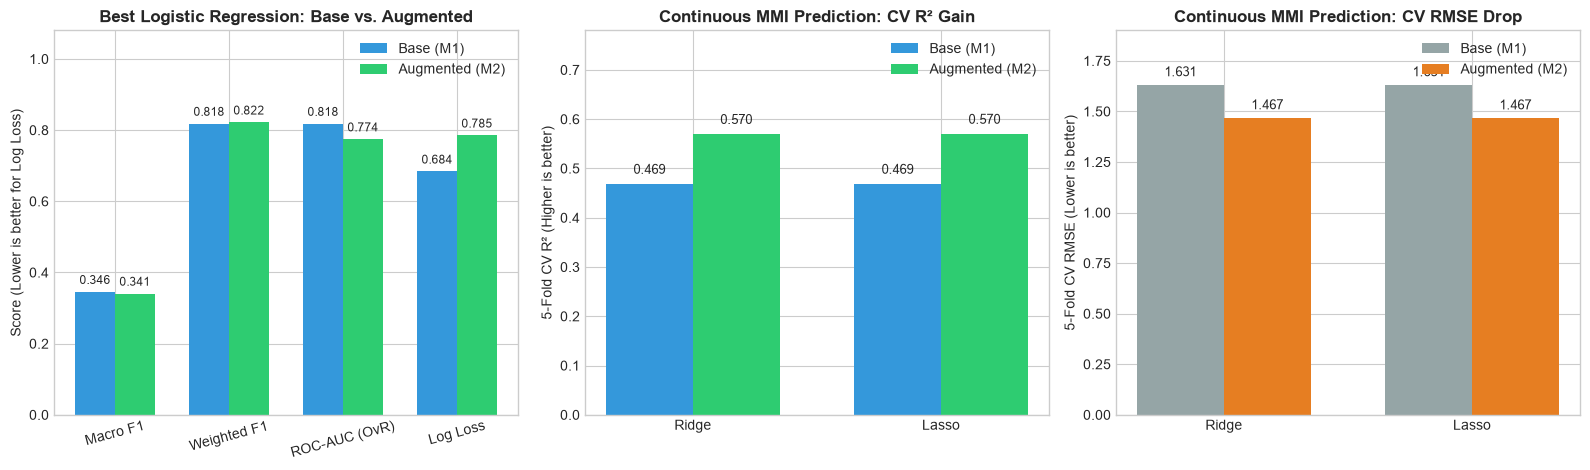

Saved: ./reports/figures/person1_base_vs_augmented.png


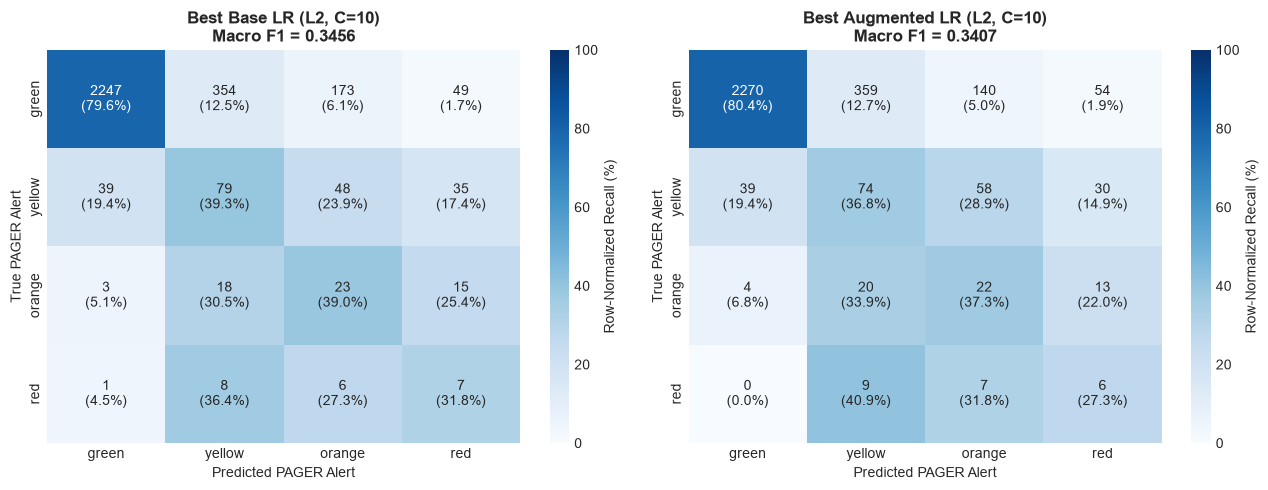

Saved: ./reports/figures/person1_confusion_matrices.png

=== Per-Class OOF Report: Best Base Logistic Regression ===
              precision    recall  f1-score   support

       green     0.9812    0.7960    0.8789      2823
      yellow     0.1721    0.3930    0.2394       201
      orange     0.0920    0.3898    0.1489        59
         red     0.0660    0.3182    0.1094        22

    accuracy                         0.7588      3105
   macro avg     0.3278    0.4743    0.3441      3105
weighted avg     0.9055    0.7588    0.8182      3105

=== Per-Class OOF Report: Best Augmented Logistic Regression ===
              precision    recall  f1-score   support

       green     0.9814    0.8041    0.8840      2823
      yellow     0.1602    0.3682    0.2232       201
      orange     0.0969    0.3729    0.1538        59
         red     0.0583    0.2727    0.0960        22

    accuracy                         0.7639      3105
   macro avg     0.3242    0.4545    0.3393      3105
wei

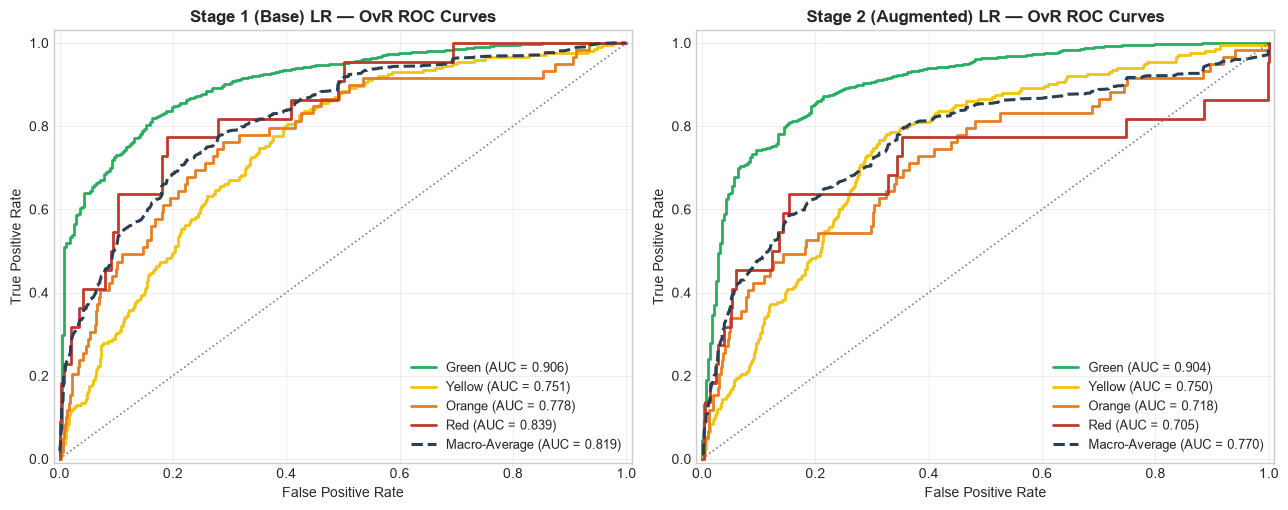

Saved: ./reports/figures/person1_roc_curves.png


In [9]:
# Person 1 (Analysis): Two-Stage Comparison Tables, Delta Charts, Confusion Matrices & ROC Curves
from sklearn.metrics import confusion_matrix, classification_report

os.makedirs(f"{REPORTS_DIR}/figures", exist_ok=True)
class_names = [INV_ALERT_MAP[i] for i in range(len(ALERT_MAP))]

# 1. Penalty-Family Classification Comparison Table (Base vs. Augmented)
best_pen_base = df_lr_base.groupby('penalty', as_index=False).first().set_index('penalty')
best_pen_aug  = df_lr_aug.groupby('penalty', as_index=False).first().set_index('penalty')

p1_cls_rows = []
for pen_label, pen_key in [('LR (L2 / Ridge)', 'l2'), ('LR (L1 / Lasso)', 'l1'), ('LR (ElasticNet)', 'elasticnet')]:
    rb, ra = best_pen_base.loc[pen_key], best_pen_aug.loc[pen_key]
    p1_cls_rows.append({
        'Model': pen_label,
        'Base Macro F1': rb['mean_macro_f1'],
        'Aug Macro F1': ra['mean_macro_f1'],
        'Δ Macro F1': ra['mean_macro_f1'] - rb['mean_macro_f1'],
        'Base Weighted F1': rb['mean_weighted_f1'],
        'Aug Weighted F1': ra['mean_weighted_f1'],
        'Base ROC-AUC': rb['mean_roc_auc'],
        'Aug ROC-AUC': ra['mean_roc_auc'],
        'Δ ROC-AUC': ra['mean_roc_auc'] - rb['mean_roc_auc'],
        'Base Log Loss': rb['mean_log_loss'],
        'Aug Log Loss': ra['mean_log_loss'],
        'Δ Log Loss': ra['mean_log_loss'] - rb['mean_log_loss'],
    })

# Add overall best row
b_top, a_top = df_lr_base.iloc[0], df_lr_aug.iloc[0]
p1_cls_rows.append({
    'Model': 'LR (Best Overall)',
    'Base Macro F1': b_top['mean_macro_f1'],
    'Aug Macro F1': a_top['mean_macro_f1'],
    'Δ Macro F1': a_top['mean_macro_f1'] - b_top['mean_macro_f1'],
    'Base Weighted F1': b_top['mean_weighted_f1'],
    'Aug Weighted F1': a_top['mean_weighted_f1'],
    'Base ROC-AUC': b_top['mean_roc_auc'],
    'Aug ROC-AUC': a_top['mean_roc_auc'],
    'Δ ROC-AUC': a_top['mean_roc_auc'] - b_top['mean_roc_auc'],
    'Base Log Loss': b_top['mean_log_loss'],
    'Aug Log Loss': a_top['mean_log_loss'],
    'Δ Log Loss': a_top['mean_log_loss'] - b_top['mean_log_loss'],
})

df_p1_comparison = pd.DataFrame(p1_cls_rows)
print("=== Person 1 Classification: Stage 1 (Base) vs. Stage 2 (Augmented) ===")
print(df_p1_comparison.round(4).to_string(index=False))

# 2. Figure 1: Base vs. Augmented Bar Charts (Classification + MMI Regression)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Panel A: LR Classification Metrics (Best Base vs. Best Augmented)
cls_metrics = ['Macro F1', 'Weighted F1', 'ROC-AUC (OvR)', 'Log Loss']
base_cls_vals = [b_top['mean_macro_f1'], b_top['mean_weighted_f1'], b_top['mean_roc_auc'], b_top['mean_log_loss']]
aug_cls_vals  = [a_top['mean_macro_f1'], a_top['mean_weighted_f1'], a_top['mean_roc_auc'], a_top['mean_log_loss']]

x = np.arange(len(cls_metrics))
w = 0.35
b1 = axes[0].bar(x - w/2, base_cls_vals, width=w, label='Base (M1)', color='#3498db')
b2 = axes[0].bar(x + w/2, aug_cls_vals,  width=w, label='Augmented (M2)', color='#2ecc71')
axes[0].set_xticks(x)
axes[0].set_xticklabels(cls_metrics, rotation=15)
axes[0].set_ylim(0, 1.08)
axes[0].set_ylabel('Score (Lower is better for Log Loss)')
axes[0].set_title('Best Logistic Regression: Base vs. Augmented', fontweight='bold')
axes[0].legend(loc='upper right')
for bars in [b1, b2]:
    for bar in bars:
        h = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2, h + 0.015, f"{h:.3f}", ha='center', va='bottom', fontsize=8.5)

# Panel B: MMI Regression CV R^2 (Base vs. Augmented)
reg_models = ['Ridge', 'Lasso']
r2_base = [df_mmi_summary.query("Model == @m and `Feature Set` == 'Base'")['CV R2'].values[0] for m in reg_models]
r2_aug  = [df_mmi_summary.query("Model == @m and `Feature Set` == 'Augmented'")['CV R2'].values[0] for m in reg_models]

x_r = np.arange(len(reg_models))
b3 = axes[1].bar(x_r - w/2, r2_base, width=w, label='Base (M1)', color='#3498db')
b4 = axes[1].bar(x_r + w/2, r2_aug,  width=w, label='Augmented (M2)', color='#2ecc71')
axes[1].set_xticks(x_r)
axes[1].set_xticklabels(reg_models)
axes[1].set_ylim(0, 0.78)
axes[1].set_ylabel('5-Fold CV R² (Higher is better)')
axes[1].set_title('Continuous MMI Prediction: CV R² Gain', fontweight='bold')
axes[1].legend(loc='upper right')
for bars in [b3, b4]:
    for bar in bars:
        h = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.015, f"{h:.3f}", ha='center', va='bottom', fontsize=9)

# Panel C: MMI Regression CV RMSE (Base vs. Augmented)
rmse_base = [df_mmi_summary.query("Model == @m and `Feature Set` == 'Base'")['CV RMSE'].values[0] for m in reg_models]
rmse_aug  = [df_mmi_summary.query("Model == @m and `Feature Set` == 'Augmented'")['CV RMSE'].values[0] for m in reg_models]

b5 = axes[2].bar(x_r - w/2, rmse_base, width=w, label='Base (M1)', color='#95a5a6')
b6 = axes[2].bar(x_r + w/2, rmse_aug,  width=w, label='Augmented (M2)', color='#e67e22')
axes[2].set_xticks(x_r)
axes[2].set_xticklabels(reg_models)
axes[2].set_ylim(0, 1.90)
axes[2].set_ylabel('5-Fold CV RMSE (Lower is better)')
axes[2].set_title('Continuous MMI Prediction: CV RMSE Drop', fontweight='bold')
axes[2].legend(loc='upper right')
for bars in [b5, b6]:
    for bar in bars:
        h = bar.get_height()
        axes[2].text(bar.get_x() + bar.get_width()/2, h + 0.03, f"{h:.3f}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
fig1_path = f"{REPORTS_DIR}/figures/person1_base_vs_augmented.png"
plt.savefig(fig1_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {fig1_path}")

# 3. Figure 2: 5-Fold OOF Confusion Matrices (Raw Counts + Row-Normalized Recall %)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm_configs = [
    (oof_lr_base['preds'],
     f"Best Base LR ({best_lr_base_params['penalty'].upper()}, C={best_lr_base_params['C']:g})\n"
     f"Macro F1 = {b_top['mean_macro_f1']:.4f}",
     axes[0]),
    (oof_lr_aug['preds'],
     f"Best Augmented LR ({best_lr_aug_params['penalty'].upper()}, C={best_lr_aug_params['C']:g})\n"
     f"Macro F1 = {a_top['mean_macro_f1']:.4f}",
     axes[1]),
]

for y_pred_oof, title, ax in cm_configs:
    cm = confusion_matrix(y_alert_p1, y_pred_oof, labels=list(range(len(ALERT_MAP))))
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100.0
    annot = np.array([
        [f"{cm[i, j]}\n({cm_pct[i, j]:.1f}%)" for j in range(len(ALERT_MAP))]
        for i in range(len(ALERT_MAP))
    ])
    sns.heatmap(cm_pct, annot=annot, fmt='', cmap='Blues', vmin=0, vmax=100,
                xticklabels=class_names, yticklabels=class_names,
                cbar_kws={'label': 'Row-Normalized Recall (%)'}, ax=ax)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Predicted PAGER Alert')
    ax.set_ylabel('True PAGER Alert')

plt.tight_layout()
fig2_path = f"{REPORTS_DIR}/figures/person1_confusion_matrices.png"
plt.savefig(fig2_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {fig2_path}")

# Print Per-Class Classification Reports
print("\n=== Per-Class OOF Report: Best Base Logistic Regression ===")
print(classification_report(y_alert_p1, oof_lr_base['preds'], target_names=class_names, digits=4))

print("=== Per-Class OOF Report: Best Augmented Logistic Regression ===")
print(classification_report(y_alert_p1, oof_lr_aug['preds'], target_names=class_names, digits=4))

# 4. Figure 3: Multi-Class One-vs-Rest ROC Curves (Base vs. Augmented)
y_bin = label_binarize(y_alert_p1, classes=list(range(len(ALERT_MAP))))
alert_colors = {'green': '#27ae60', 'yellow': '#f1c40f', 'orange': '#e67e22', 'red': '#c0392b'}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
roc_configs = [
    (oof_lr_base['probs'], f"Stage 1 (Base) LR — OvR ROC Curves", axes[0]),
    (oof_lr_aug['probs'],  f"Stage 2 (Augmented) LR — OvR ROC Curves", axes[1]),
]

for y_prob_oof, title, ax in roc_configs:
    fpr_dict, tpr_dict, auc_dict = {}, {}, {}
    for c_idx, c_name in enumerate(class_names):
        fpr_dict[c_idx], tpr_dict[c_idx], _ = roc_curve(y_bin[:, c_idx], y_prob_oof[:, c_idx])
        auc_dict[c_idx] = auc(fpr_dict[c_idx], tpr_dict[c_idx])
        ax.plot(fpr_dict[c_idx], tpr_dict[c_idx], color=alert_colors[c_name], lw=2.0,
                label=f"{c_name.capitalize()} (AUC = {auc_dict[c_idx]:.3f})")

    # Macro-average ROC curve
    all_fpr = np.unique(np.concatenate([fpr_dict[i] for i in range(len(ALERT_MAP))]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(len(ALERT_MAP)):
        mean_tpr += np.interp(all_fpr, fpr_dict[i], tpr_dict[i])
    mean_tpr /= len(ALERT_MAP)
    macro_auc = auc(all_fpr, mean_tpr)

    ax.plot(all_fpr, mean_tpr, color='#2c3e50', linestyle='--', lw=2.2,
            label=f"Macro-Average (AUC = {macro_auc:.3f})")
    ax.plot([0, 1], [0, 1], color='gray', linestyle=':', lw=1.2)
    ax.set_xlim([-0.01, 1.01])
    ax.set_ylim([-0.01, 1.03])
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(title, fontweight='bold')
    ax.legend(loc='lower right', fontsize=9)
    ax.grid(alpha=0.3)

plt.tight_layout()
fig3_path = f"{REPORTS_DIR}/figures/person1_roc_curves.png"
plt.savefig(fig3_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {fig3_path}")

### 4.5 Interpretability & Feature Significance Analysis
Inspect learned linear model weights and run holdout permutation importance significance tests ($n = 30$ repeats, one-sided $t$-test at $\alpha = 0.05$) on the **Augmented** feature set to answer:
1. Which physical, sensor, and tectonic features carry the largest standardized weights in **Logistic Regression (`alert`)** and **Lasso/Ridge (`mmi`)**?
2. Do Module 2's **`dist_to_nearest_fault_km`** and **`gmm_prob_*`** posterior features carry statistically significant predictive weight individually and as a tectonic feature group?
3. Export coefficient (`person1_feature_coefficients.png`) and permutation importance (`person1_permutation_importance.png`) figures to `reports/figures/`.

=== Augmented Logistic Regression (L2, C=10) Coefficient Audit ===
  Non-zero features retained:       61 / 61
  Module 2 fault features retained: 25 / 25

--- Top 15 Features by Mean |Coefficient| in Augmented Logistic Regression ---
                           source  lr_green  lr_yellow  lr_orange  lr_red  lr_mean_abs
z_ecef            Module 1 (Base)   -4.4570     6.1025    -4.3737  2.7282       4.4153
lat_rad           Module 1 (Base)    2.6485    -2.3022     3.2794 -3.6257       2.9640
latitude          Module 1 (Base)    2.6485    -2.3022     3.2794 -3.6257       2.9640
depth             Module 1 (Base)    3.0028     1.4312     0.7684 -5.2024       2.6012
gmm_prob_11  Module 2 (Fault/GMM)   -1.6685    -1.2556    -1.2486  4.1727       2.0864
gmm_cluster  Module 2 (Fault/GMM)    1.2143     1.7806     1.0285 -4.0234       2.0117
gmm_prob_6   Module 2 (Fault/GMM)   -1.1810    -0.9036    -1.2145  3.2991       1.6495
gmm_prob_19  Module 2 (Fault/GMM)    1.2927    -3.1885     1.9657 -0.

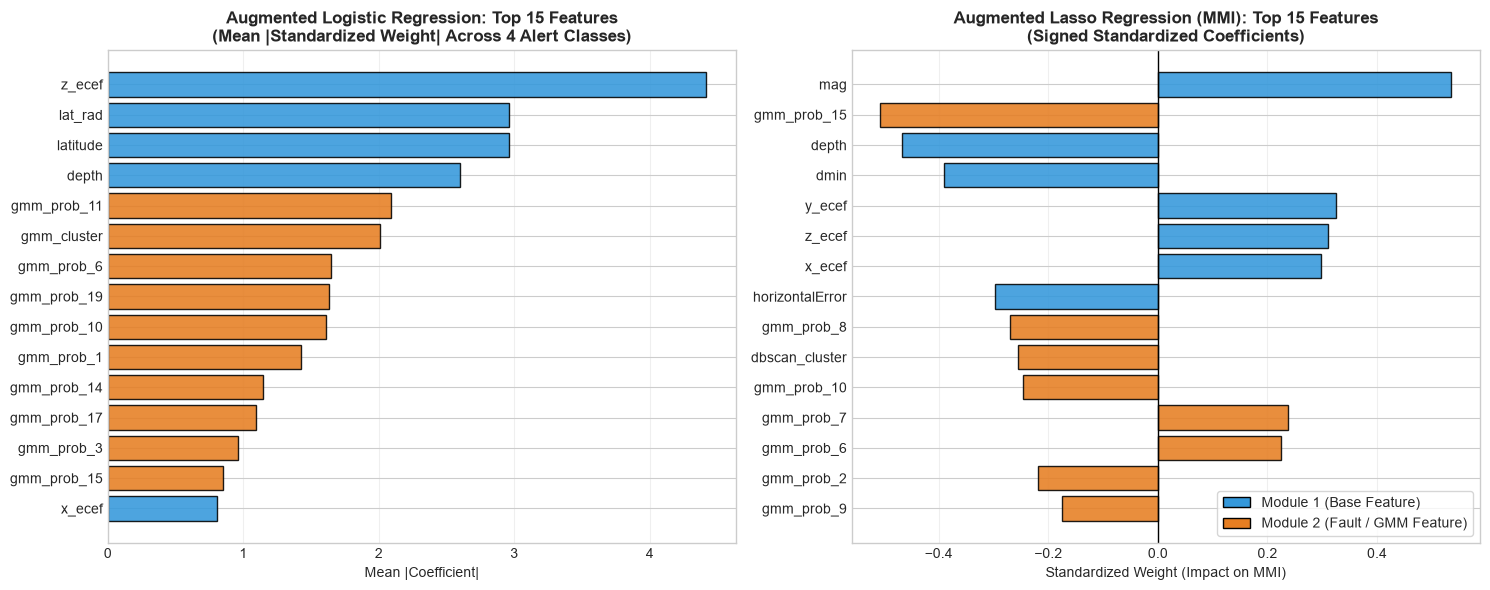

Saved: ./reports/figures/person1_feature_coefficients.png



=== Permutation Importance Statistical Significance (Holdout Test, 30 Repeats, alpha=0.05) ===
  Statistically significant Module 2 features (LR ROC-AUC, p<0.05): 20 / 25
  Statistically significant Module 2 features (MMI R², p<0.05):     16 / 25

--- Top 10 Features by Permutation Importance: Augmented LR (Δ ROC-AUC OvR) ---
    feature               source  lr_auc_imp  lr_auc_std  lr_auc_pval  lr_f1_imp
     z_ecef      Module 1 (Base)     0.15028     0.02453          0.0    0.06242
    lat_rad      Module 1 (Base)     0.13094     0.02472          0.0    0.05733
   latitude      Module 1 (Base)     0.13094     0.02472          0.0    0.05733
     x_ecef      Module 1 (Base)     0.07554     0.01359          0.0    0.01840
gmm_prob_11 Module 2 (Fault/GMM)     0.06732     0.01666          0.0   -0.00728
gmm_cluster Module 2 (Fault/GMM)     0.05606     0.01510          0.0    0.01448
 gmm_prob_6 Module 2 (Fault/GMM)     0.04762     0.00845          0.0   -0.00289
      depth      Module


=== Joint Feature-Group Permutation Test (30 Repeats, Holdout Test Set) ===
                        Feature Group  LR Δ ROC-AUC  LR p-value  MMI Δ R²  MMI p-value
      All Module 1 Base Features (39)       0.24961         0.0   0.62326      0.00000
 All Module 2 Fault/GMM Features (25)       0.16809         0.0   0.31672      0.00000
GMM Posteriors Block (gmm_prob_0..19)       0.18868         0.0   0.26189      0.00000
    dist_to_nearest_fault_km (single)       0.01411         0.0   0.00176      0.00007
 DBSCAN + GMM Meta (cluster/noise/ll)       0.06563         0.0   0.03271      0.00000


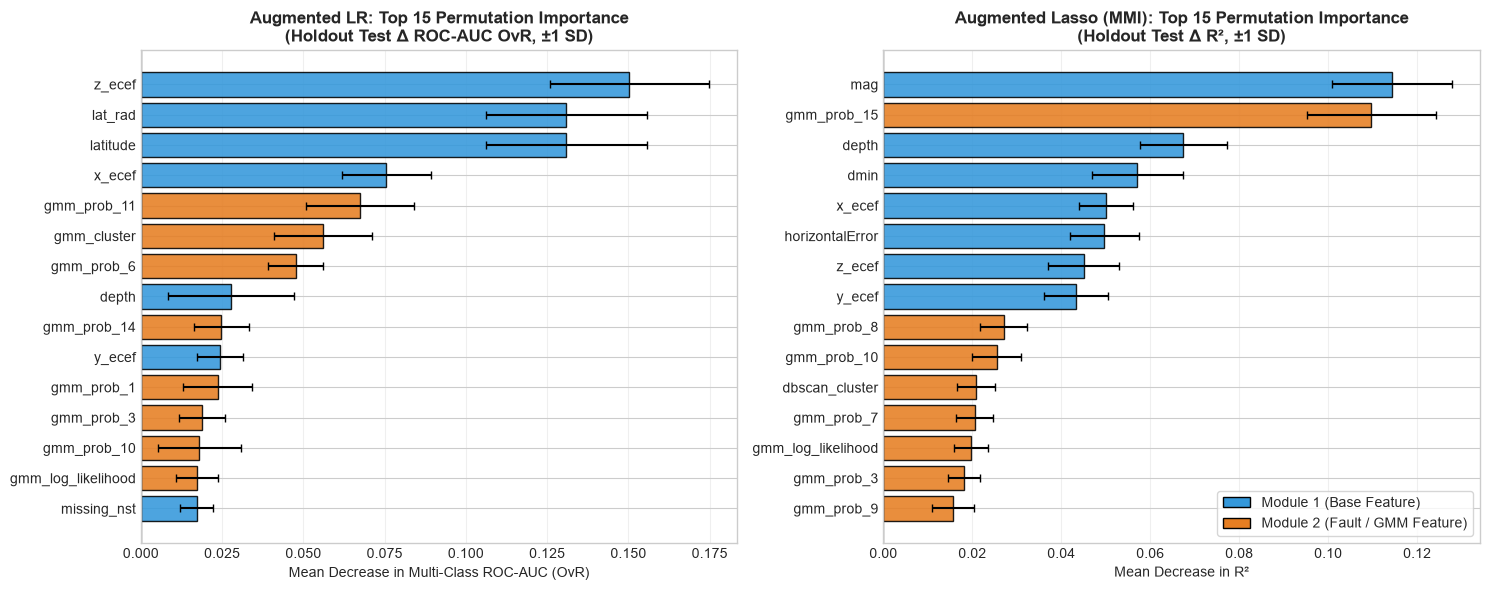

Saved: ./reports/figures/person1_permutation_importance.png


In [10]:
# Person 1 (Interpretability): Coefficient Audit & Permutation Importance Significance Tests
from scipy.stats import ttest_1samp

class_names = [INV_ALERT_MAP[i] for i in range(len(ALERT_MAP))]
fault_set = set(NEW_FAULT_FEATURES)
gmm_prob_cols = [c for c in AUGMENTED_FEATURES if c.startswith('gmm_prob_')]

# -------------------------------------------------------------------------
# 1. Standardized Coefficient Inspection (Augmented LR + Ridge/Lasso MMI)
# -------------------------------------------------------------------------
lr_coefs = lr_aug_full_pipe.named_steps['lr'].coef_          # shape: (4, n_features)
lasso_mmi_coefs = lasso_aug_full_pipe.named_steps['reg'].coef_
ridge_mmi_coefs = ridge_aug_full_pipe.named_steps['reg'].coef_

df_coef = pd.DataFrame(lr_coefs.T, index=AUGMENTED_FEATURES, columns=[f"lr_{c}" for c in class_names])
df_coef['lr_mean_abs'] = np.abs(lr_coefs).mean(axis=0)
df_coef['lr_max_abs'] = np.abs(lr_coefs).max(axis=0)
df_coef['lr_nonzero'] = df_coef['lr_max_abs'] > 1e-6
df_coef['mmi_lasso_w'] = lasso_mmi_coefs
df_coef['mmi_ridge_w'] = ridge_mmi_coefs
df_coef['source'] = ['Module 2 (Fault/GMM)' if f in fault_set else 'Module 1 (Base)' for f in AUGMENTED_FEATURES]

n_lr_nz = int(df_coef['lr_nonzero'].sum())
n_lr_fault_nz = int(df_coef.loc[NEW_FAULT_FEATURES, 'lr_nonzero'].sum())
print(f"=== Augmented Logistic Regression ({best_lr_aug_params['penalty'].upper()}, C={best_lr_aug_params['C']:g}) Coefficient Audit ===")
print(f"  Non-zero features retained:       {n_lr_nz} / {len(AUGMENTED_FEATURES)}")
print(f"  Module 2 fault features retained: {n_lr_fault_nz} / {len(NEW_FAULT_FEATURES)}\n")

print("--- Top 15 Features by Mean |Coefficient| in Augmented Logistic Regression ---")
top15_lr = df_coef.sort_values('lr_mean_abs', ascending=False).head(15)
print(top15_lr[['source', 'lr_green', 'lr_yellow', 'lr_orange', 'lr_red', 'lr_mean_abs']].round(4).to_string())

print("\n--- Top 12 Module 2 Tectonic Features (LR Alert & Lasso/Ridge MMI Weights) ---")
fault_audit = df_coef.loc[NEW_FAULT_FEATURES].sort_values(
    by=['lr_mean_abs', 'mmi_lasso_w'], key=lambda s: s.abs(), ascending=False
)
# Ensure dist_to_nearest_fault_km is always printed clearly
print(fault_audit[['lr_mean_abs', 'lr_red', 'mmi_lasso_w', 'mmi_ridge_w']].head(12).round(4).to_string())
if 'dist_to_nearest_fault_km' in df_coef.index:
    r_dist = df_coef.loc['dist_to_nearest_fault_km']
    print(f"\nExplicit Audit — dist_to_nearest_fault_km:")
    print(f"  LR weights [green, yellow, orange, red]: "
          f"[{r_dist['lr_green']:+.4f}, {r_dist['lr_yellow']:+.4f}, {r_dist['lr_orange']:+.4f}, {r_dist['lr_red']:+.4f}] "
          f"| mean|w|={r_dist['lr_mean_abs']:.4f}")
    print(f"  MMI weights -> Lasso: {r_dist['mmi_lasso_w']:+.4f} | Ridge: {r_dist['mmi_ridge_w']:+.4f}")

# -------------------------------------------------------------------------
# 2. Figure 4: Top Feature Weights (LR Alert + Lasso MMI)
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel A: Augmented LR Top 15 by Mean |w|
plot_lr = top15_lr.iloc[::-1]
colors_lr = ['#e67e22' if s == 'Module 2 (Fault/GMM)' else '#3498db' for s in plot_lr['source']]
axes[0].barh(plot_lr.index, plot_lr['lr_mean_abs'], color=colors_lr, edgecolor='black', alpha=0.88)
axes[0].set_title('Augmented Logistic Regression: Top 15 Features\n(Mean |Standardized Weight| Across 4 Alert Classes)', fontweight='bold')
axes[0].set_xlabel('Mean |Coefficient|')
axes[0].grid(axis='x', alpha=0.3)

# Panel B: Augmented Lasso (MMI) Top 15 by |w| (showing signed direction)
top15_mmi = df_coef.reindex(df_coef['mmi_lasso_w'].abs().sort_values(ascending=False).index).head(15).iloc[::-1]
colors_mmi = ['#e67e22' if s == 'Module 2 (Fault/GMM)' else '#3498db' for s in top15_mmi['source']]
axes[1].barh(top15_mmi.index, top15_mmi['mmi_lasso_w'], color=colors_mmi, edgecolor='black', alpha=0.88)
axes[1].axvline(0, color='black', lw=1.0)
axes[1].set_title('Augmented Lasso Regression (MMI): Top 15 Features\n(Signed Standardized Coefficients)', fontweight='bold')
axes[1].set_xlabel('Standardized Weight (Impact on MMI)')
axes[1].grid(axis='x', alpha=0.3)

# Shared color legend
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor='#3498db', edgecolor='black', label='Module 1 (Base Feature)'),
    Patch(facecolor='#e67e22', edgecolor='black', label='Module 2 (Fault / GMM Feature)'),
]
axes[1].legend(handles=legend_handles, loc='lower right', frameon=True)

plt.tight_layout()
fig4_path = f"{REPORTS_DIR}/figures/person1_feature_coefficients.png"
plt.savefig(fig4_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {fig4_path}")

# -------------------------------------------------------------------------
# 3. Holdout Permutation Importance & Statistical Significance (n=30 repeats)
# -------------------------------------------------------------------------
def one_sided_p_greater(samples):
    """One-sided t-test testing H0: mean(importance) <= 0 vs H1: mean(importance) > 0."""
    arr = np.asarray(samples, dtype=float)
    if np.mean(arr) <= 0 or np.std(arr, ddof=1) == 0:
        return 1.0
    t_stat, p_two = ttest_1samp(arr, 0.0)
    return float(p_two / 2.0) if t_stat > 0 else float(1.0 - p_two / 2.0)

perm_lr_auc = permutation_importance(
    lr_aug_full_pipe, X_test_aug_p1, y_test_alert_p1,
    scoring='roc_auc_ovr', n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1
)
perm_lr_f1 = permutation_importance(
    lr_aug_full_pipe, X_test_aug_p1, y_test_alert_p1,
    scoring='f1_macro', n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1
)
perm_mmi_r2 = permutation_importance(
    lasso_aug_full_pipe, X_test_aug_p1, y_mmi_test_p1,
    scoring='r2', n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1
)

df_perm = pd.DataFrame({
    'feature': AUGMENTED_FEATURES,
    'source': ['Module 2 (Fault/GMM)' if f in fault_set else 'Module 1 (Base)' for f in AUGMENTED_FEATURES],
    'lr_auc_imp': perm_lr_auc.importances_mean,
    'lr_auc_std': perm_lr_auc.importances_std,
    'lr_auc_pval': [one_sided_p_greater(perm_lr_auc.importances[i]) for i in range(len(AUGMENTED_FEATURES))],
    'lr_f1_imp': perm_lr_f1.importances_mean,
    'lr_f1_pval': [one_sided_p_greater(perm_lr_f1.importances[i]) for i in range(len(AUGMENTED_FEATURES))],
    'mmi_r2_imp': perm_mmi_r2.importances_mean,
    'mmi_r2_std': perm_mmi_r2.importances_std,
    'mmi_r2_pval': [one_sided_p_greater(perm_mmi_r2.importances[i]) for i in range(len(AUGMENTED_FEATURES))],
})

sig_lr_fault = df_perm[(df_perm['source'] == 'Module 2 (Fault/GMM)') & (df_perm['lr_auc_pval'] < 0.05)]
sig_mmi_fault = df_perm[(df_perm['source'] == 'Module 2 (Fault/GMM)') & (df_perm['mmi_r2_pval'] < 0.05)]

print("\n=== Permutation Importance Statistical Significance (Holdout Test, 30 Repeats, alpha=0.05) ===")
print(f"  Statistically significant Module 2 features (LR ROC-AUC, p<0.05): {len(sig_lr_fault)} / {len(NEW_FAULT_FEATURES)}")
print(f"  Statistically significant Module 2 features (MMI R², p<0.05):     {len(sig_mmi_fault)} / {len(NEW_FAULT_FEATURES)}")

print("\n--- Top 10 Features by Permutation Importance: Augmented LR (Δ ROC-AUC OvR) ---")
print(df_perm.sort_values('lr_auc_imp', ascending=False)[
    ['feature', 'source', 'lr_auc_imp', 'lr_auc_std', 'lr_auc_pval', 'lr_f1_imp']
].head(10).round(5).to_string(index=False))

print("\n--- Top 10 Features by Permutation Importance: Augmented Lasso MMI (Δ R²) ---")
print(df_perm.sort_values('mmi_r2_imp', ascending=False)[
    ['feature', 'source', 'mmi_r2_imp', 'mmi_r2_std', 'mmi_r2_pval']
].head(10).round(5).to_string(index=False))

# -------------------------------------------------------------------------
# 4. Feature-Group Permutation Test (accounts for collinearity in gmm_prob_*)
# -------------------------------------------------------------------------
feature_groups = {
    'All Module 1 Base Features (39)': BASE_FEATURES,
    'All Module 2 Fault/GMM Features (25)': NEW_FAULT_FEATURES,
    'GMM Posteriors Block (gmm_prob_0..19)': gmm_prob_cols,
    'dist_to_nearest_fault_km (single)': ['dist_to_nearest_fault_km'] if 'dist_to_nearest_fault_km' in AUGMENTED_FEATURES else [],
    'DBSCAN + GMM Meta (cluster/noise/ll)': [c for c in NEW_FAULT_FEATURES if c not in gmm_prob_cols and c != 'dist_to_nearest_fault_km'],
}

rng = np.random.default_rng(RANDOM_STATE)
base_lr_auc = roc_auc_score(y_test_alert_p1, lr_aug_full_pipe.predict_proba(X_test_aug_p1), multi_class='ovr', average='macro')
base_mmi_r2 = r2_score(y_mmi_test_p1, lasso_aug_full_pipe.predict(X_test_aug_p1))

group_rows = []
for g_name, g_cols in feature_groups.items():
    if not g_cols:
        continue
    auc_drops, r2_drops = [], []
    for _ in range(30):
        X_shuf = X_test_aug_p1.copy()
        perm_idx = rng.permutation(len(X_shuf))
        # Permute all columns in the group jointly (preserves within-group structure, breaks target link)
        X_shuf[g_cols] = X_shuf[g_cols].iloc[perm_idx].values
        auc_drops.append(base_lr_auc - roc_auc_score(y_test_alert_p1, lr_aug_full_pipe.predict_proba(X_shuf), multi_class='ovr', average='macro'))
        r2_drops.append(base_mmi_r2 - r2_score(y_mmi_test_p1, lasso_aug_full_pipe.predict(X_shuf)))
    group_rows.append({
        'Feature Group': g_name,
        'LR Δ ROC-AUC': np.mean(auc_drops),
        'LR p-value': one_sided_p_greater(auc_drops),
        'MMI Δ R²': np.mean(r2_drops),
        'MMI p-value': one_sided_p_greater(r2_drops),
    })

df_group_perm = pd.DataFrame(group_rows)
print("\n=== Joint Feature-Group Permutation Test (30 Repeats, Holdout Test Set) ===")
print(df_group_perm.round(5).to_string(index=False))

# -------------------------------------------------------------------------
# 5. Figure 5: Permutation Importance Rankings (LR Alert + Lasso MMI)
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

top15_perm_lr = df_perm.sort_values('lr_auc_imp', ascending=False).head(15).iloc[::-1]
c_p_lr = ['#e67e22' if s == 'Module 2 (Fault/GMM)' else '#3498db' for s in top15_perm_lr['source']]
axes[0].barh(top15_perm_lr['feature'], top15_perm_lr['lr_auc_imp'], xerr=top15_perm_lr['lr_auc_std'],
             color=c_p_lr, edgecolor='black', alpha=0.88, capsize=3)
axes[0].axvline(0, color='black', lw=0.9)
axes[0].set_title('Augmented LR: Top 15 Permutation Importance\n(Holdout Test Δ ROC-AUC OvR, ±1 SD)', fontweight='bold')
axes[0].set_xlabel('Mean Decrease in Multi-Class ROC-AUC (OvR)')
axes[0].grid(axis='x', alpha=0.3)

top15_perm_mmi = df_perm.sort_values('mmi_r2_imp', ascending=False).head(15).iloc[::-1]
c_p_mmi = ['#e67e22' if s == 'Module 2 (Fault/GMM)' else '#3498db' for s in top15_perm_mmi['source']]
axes[1].barh(top15_perm_mmi['feature'], top15_perm_mmi['mmi_r2_imp'], xerr=top15_perm_mmi['mmi_r2_std'],
             color=c_p_mmi, edgecolor='black', alpha=0.88, capsize=3)
axes[1].axvline(0, color='black', lw=0.9)
axes[1].set_title('Augmented Lasso (MMI): Top 15 Permutation Importance\n(Holdout Test Δ R², ±1 SD)', fontweight='bold')
axes[1].set_xlabel('Mean Decrease in R²')
axes[1].grid(axis='x', alpha=0.3)
axes[1].legend(handles=legend_handles, loc='lower right', frameon=True)

plt.tight_layout()
fig5_path = f"{REPORTS_DIR}/figures/person1_permutation_importance.png"
plt.savefig(fig5_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {fig5_path}")

### 4.6 Model Serialization & Out-of-Fold (OOF) Prediction Export
Export all Person 1 artifacts for Module 4 stacking and end-to-end reproducibility:
1. **Serialized Final Model**: Save the full-fit tuned Augmented Logistic Regression pipeline (`StandardScaler` + `LogisticRegression`) to `artifacts/models/logistic_regression_aug.joblib` and run a round-trip load verification.
2. **OOF Probability Predictions**: Export 5-fold cross-validated training probabilities (`oof_train_person1.parquet`) and holdout test probabilities (`oof_test_person1.parquet`) following the Module 3 $\rightarrow$ Module 4 data contract (`event_id`, `true_label` as `int32`, `lr_prob_<class>` as `float64`, with all row sums equal to $1.0$).
3. **Holdout Test Audit**: Log final holdout test Macro F1, Weighted F1, ROC-AUC (OvR), and Log Loss.

In [11]:
# Person 1 (Deliverables): Model Serialization & OOF Prediction Export for Module 4
os.makedirs(f"{ARTIFACTS_DIR}/models", exist_ok=True)
os.makedirs(f"{ARTIFACTS_DIR}/oof_predictions", exist_ok=True)

class_names = [INV_ALERT_MAP[i] for i in range(len(ALERT_MAP))]
lr_prob_cols = [f"lr_prob_{c}" for c in class_names]

# 1. Serialize best Augmented Logistic Regression pipeline & verify round-trip load
lr_model_path = f"{ARTIFACTS_DIR}/models/logistic_regression_aug.joblib"
joblib.dump(lr_aug_full_pipe, lr_model_path)

loaded_lr_pipe = joblib.load(lr_model_path)
test_lr_probs = loaded_lr_pipe.predict_proba(X_test_aug_p1).astype(np.float64)
test_lr_preds = loaded_lr_pipe.predict(X_test_aug_p1)

assert np.allclose(test_lr_probs, lr_aug_full_pipe.predict_proba(X_test_aug_p1)), \
    "Round-trip joblib load mismatch!"
print(f"✓ Serialized & verified model: {lr_model_path}")

# 2. Extract 5-fold CV OOF probabilities from Step 4.2 (best Augmented LR config)
oof_lr_train_probs = oof_lr_aug['probs'].astype(np.float64)

# Sanity checks: bounds [0, 1] and row sums == 1.0
assert np.all((oof_lr_train_probs >= 0.0) & (oof_lr_train_probs <= 1.0)), "Train OOF probs out of [0, 1]!"
assert np.all((test_lr_probs >= 0.0) & (test_lr_probs <= 1.0)), "Test probs out of [0, 1]!"
assert np.allclose(oof_lr_train_probs.sum(axis=1), 1.0, atol=1e-6), "Train OOF probabilities do not sum to 1.0!"
assert np.allclose(test_lr_probs.sum(axis=1), 1.0, atol=1e-6), "Test probabilities do not sum to 1.0!"
print("✓ Probability sanity checks passed (all rows in [0, 1] and sum to 1.0).")

# 3. Build DataFrames conforming to Module 3 -> Module 4 OOF contract
oof_train_p1_df = pd.DataFrame({
    'event_id': train_aug['event_id'].astype(str).values,
    'true_label': y_alert_p1.astype(np.int32),
})
for i, col in enumerate(lr_prob_cols):
    oof_train_p1_df[col] = oof_lr_train_probs[:, i].astype(np.float64)

oof_test_p1_df = pd.DataFrame({
    'event_id': test_aug['event_id'].astype(str).values,
    'true_label': y_test_alert_p1.astype(np.int32),
})
for i, col in enumerate(lr_prob_cols):
    oof_test_p1_df[col] = test_lr_probs[:, i].astype(np.float64)

# 4. Export to Parquet
oof_train_p1_path = f"{ARTIFACTS_DIR}/oof_predictions/oof_train_person1.parquet"
oof_test_p1_path  = f"{ARTIFACTS_DIR}/oof_predictions/oof_test_person1.parquet"

oof_train_p1_df.to_parquet(oof_train_p1_path, index=False)
oof_test_p1_df.to_parquet(oof_test_p1_path, index=False)

# Verify reload & schema
_chk_tr = pd.read_parquet(oof_train_p1_path)
_chk_te = pd.read_parquet(oof_test_p1_path)
assert _chk_tr.shape == (len(train_aug), 6), f"Unexpected train OOF shape: {_chk_tr.shape}"
assert _chk_te.shape == (len(test_aug), 6), f"Unexpected test OOF shape: {_chk_te.shape}"
assert (_chk_tr['event_id'].values == train_aug['event_id'].astype(str).values).all()
assert (_chk_te['event_id'].values == test_aug['event_id'].astype(str).values).all()

print(f"✓ Exported Train OOF: {oof_train_p1_path} | shape={_chk_tr.shape}")
print(f"✓ Exported Test OOF:  {oof_test_p1_path} | shape={_chk_te.shape}")
print("\nSchema & Dtypes:")
print(_chk_tr.dtypes.to_string())
print("\nSample Train OOF rows:")
print(_chk_tr.head(5).round(4).to_string(index=False))

# 5. Final Holdout Test Set Performance Summary (Base vs. Augmented Best LR)
test_base_scores = evaluate_p1_classification(
    y_test_alert_p1,
    lr_base_full_pipe.predict(X_test_base_p1),
    lr_base_full_pipe.predict_proba(X_test_base_p1)
)
test_aug_scores = evaluate_p1_classification(y_test_alert_p1, test_lr_preds, test_lr_probs)

print("\n=== Holdout Test Set Performance (Person 1: Best Logistic Regression) ===")
print(f"  Base LR      -> Macro F1: {test_base_scores['macro_f1']:.4f} | "
      f"Weighted F1: {test_base_scores['weighted_f1']:.4f} | "
      f"ROC-AUC: {test_base_scores['roc_auc_ovr']:.4f} | "
      f"Log Loss: {test_base_scores['log_loss']:.4f}")
print(f"  Augmented LR -> Macro F1: {test_aug_scores['macro_f1']:.4f} | "
      f"Weighted F1: {test_aug_scores['weighted_f1']:.4f} | "
      f"ROC-AUC: {test_aug_scores['roc_auc_ovr']:.4f} | "
      f"Log Loss: {test_aug_scores['log_loss']:.4f}")

✓ Serialized & verified model: ./artifacts/models/logistic_regression_aug.joblib
✓ Probability sanity checks passed (all rows in [0, 1] and sum to 1.0).
✓ Exported Train OOF: ./artifacts/oof_predictions/oof_train_person1.parquet | shape=(3105, 6)
✓ Exported Test OOF:  ./artifacts/oof_predictions/oof_test_person1.parquet | shape=(666, 6)

Schema & Dtypes:
event_id              str
true_label          int32
lr_prob_green     float64
lr_prob_yellow    float64
lr_prob_orange    float64
lr_prob_red       float64

Sample Train OOF rows:
  event_id  true_label  lr_prob_green  lr_prob_yellow  lr_prob_orange  lr_prob_red
usc000p27i           1         0.0000          0.0467          0.9533          0.0
us60008bj6           0         0.9803          0.0179          0.0018          0.0
us6000le2y           0         0.8750          0.0029          0.1220          0.0
us6000ldsf           0         0.9998          0.0000          0.0001          0.0
us7000clbu           0         0.9943          0

---
## 5. Person 2 (Parshav): Probabilistic & Discriminant Models
**Owner**: Person 2 (Parshav)

**Algorithms**:
1. Gaussian Naive Bayes
2. Linear Discriminant Analysis (LDA)
3. Quadratic Discriminant Analysis (QDA).  

___
### 5.1 Gaussian Naive Bayes — Stage 1 (Base Features)
Implement and tune Gaussian Naive Bayes (`GaussianNB`) on `BASE_FEATURES` using the shared 5-fold stratified cross-validation split:
- Sweep `var_smoothing` $\in [10^{-11}, 10^{-9}, 10^{-7}, 10^{-5}, 10^{-3}, 10^{-2}, 10^{-1}]$ to stabilize variance estimates and prevent zero-variance division errors on rare alert classes (`orange`, `red`).
- Log Macro F1, Weighted F1, and Multi-class ROC-AUC (OvR).

In [12]:
# Person 2 (Model 1): Gaussian Naive Bayes on Base Features
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Define X and y locally so Section 5 can run independently after Cells 0-3
X_base = train_base[BASE_FEATURES]
y_base = train_base['alert_label'].values

var_smoothing_values = [1e-11, 1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1]
gnb_base_results = []

for vs in var_smoothing_values:
    fold_macro_f1s = []
    fold_weighted_f1s = []
    fold_rocs = []

    for train_idx, val_idx in cv_splitter.split(X_base, y_base):
        X_tr, y_tr = X_base.iloc[train_idx], y_base[train_idx]
        X_va, y_va = X_base.iloc[val_idx], y_base[val_idx]

        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('gnb', GaussianNB(var_smoothing=vs))
        ])
        pipeline.fit(X_tr, y_tr)

        y_pred = pipeline.predict(X_va)
        y_prob = pipeline.predict_proba(X_va)

        scores = evaluate_predictions(y_va, y_pred, y_prob)
        fold_macro_f1s.append(scores['macro_f1'])
        fold_weighted_f1s.append(scores['weighted_f1'])
        fold_rocs.append(scores['roc_auc_ovr'])

    gnb_base_results.append({
        'var_smoothing': vs,
        'mean_macro_f1': np.mean(fold_macro_f1s),
        'mean_weighted_f1': np.mean(fold_weighted_f1s),
        'mean_roc_auc': np.mean(fold_rocs)
    })

df_gnb_base = pd.DataFrame(gnb_base_results).sort_values(by='mean_macro_f1', ascending=False)
best_gnb_base_params = df_gnb_base.iloc[0].to_dict()

print("GaussianNB Results on Base Features:")
print(df_gnb_base.round(4).to_string(index=False))
print("\nBest Base GaussianNB Config:", best_gnb_base_params)

GaussianNB Results on Base Features:
 var_smoothing  mean_macro_f1  mean_weighted_f1  mean_roc_auc
         0.100         0.2843            0.8411        0.7840
         0.010         0.2638            0.8267        0.7601
         0.001         0.2547            0.8098        0.7421
         0.000         0.2422            0.7787        0.7039
         0.000         0.2311            0.7409        0.6746
         0.000         0.2188            0.7130        0.6523
         0.000         0.2098            0.6846        0.6365

Best Base GaussianNB Config: {'var_smoothing': 0.1, 'mean_macro_f1': 0.2842510483705756, 'mean_weighted_f1': 0.8410828908974708, 'mean_roc_auc': 0.7839576234410325}


### 5.2 Gaussian Naive Bayes — Stage 2 (Augmented Features)
Train and tune `GaussianNB` on `AUGMENTED_FEATURES` (Base + PCA + DBSCAN + GMM fault features) using the identical 5-fold CV splits, and check the performance delta ($\Delta$) vs. Stage 1.

In [13]:
# Person 2 (Model 1): Gaussian Naive Bayes on Augmented Features
X_aug = train_aug[AUGMENTED_FEATURES]
y_aug = train_aug['alert_label'].values

gnb_aug_results = []

for vs in var_smoothing_values:
    fold_macro_f1s = []
    fold_weighted_f1s = []
    fold_rocs = []

    for train_idx, val_idx in cv_splitter.split(X_aug, y_aug):
        X_tr, y_tr = X_aug.iloc[train_idx], y_aug[train_idx]
        X_va, y_va = X_aug.iloc[val_idx], y_aug[val_idx]

        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('gnb', GaussianNB(var_smoothing=vs))
        ])
        pipeline.fit(X_tr, y_tr)

        y_pred = pipeline.predict(X_va)
        y_prob = pipeline.predict_proba(X_va)

        scores = evaluate_predictions(y_va, y_pred, y_prob)
        fold_macro_f1s.append(scores['macro_f1'])
        fold_weighted_f1s.append(scores['weighted_f1'])
        fold_rocs.append(scores['roc_auc_ovr'])

    gnb_aug_results.append({
        'var_smoothing': vs,
        'mean_macro_f1': np.mean(fold_macro_f1s),
        'mean_weighted_f1': np.mean(fold_weighted_f1s),
        'mean_roc_auc': np.mean(fold_rocs)
    })

df_gnb_aug = pd.DataFrame(gnb_aug_results).sort_values(by='mean_macro_f1', ascending=False)
best_gnb_aug_params = df_gnb_aug.iloc[0].to_dict()

print("GaussianNB Results on Augmented Features:")
print(df_gnb_aug.round(4).to_string(index=False))
print("\nBest Augmented GaussianNB Config:", best_gnb_aug_params)

# Quick delta check for GaussianNB
delta_f1 = best_gnb_aug_params['mean_macro_f1'] - best_gnb_base_params['mean_macro_f1']
delta_auc = best_gnb_aug_params['mean_roc_auc'] - best_gnb_base_params['mean_roc_auc']
print(f"\nGaussianNB Delta -> Δ Macro F1: {delta_f1:+.4f} | Δ ROC-AUC: {delta_auc:+.4f}")

GaussianNB Results on Augmented Features:
 var_smoothing  mean_macro_f1  mean_weighted_f1  mean_roc_auc
         0.100         0.2675            0.7978        0.6984
         0.010         0.2607            0.7732        0.6789
         0.001         0.2560            0.7506        0.6784
         0.000         0.2434            0.7198        0.6647
         0.000         0.2363            0.7032        0.6598
         0.000         0.2336            0.6946        0.6559
         0.000         0.2307            0.6934        0.6511

Best Augmented GaussianNB Config: {'var_smoothing': 0.1, 'mean_macro_f1': 0.267538681471622, 'mean_weighted_f1': 0.7978249857835772, 'mean_roc_auc': 0.6984103306942958}

GaussianNB Delta -> Δ Macro F1: -0.0167 | Δ ROC-AUC: -0.0855


### 5.3 Linear Discriminant Analysis (LDA) — Stage 1 (Base Features)
Implement and tune `LinearDiscriminantAnalysis` on `BASE_FEATURES` using the shared 5-fold CV split:
- Test solvers: `svd` and `eigen` (plus `lsqr` if needed).
- Test covariance shrinkage (`shrinkage='auto'`, `0.1`, `0.5`) on supported solvers (`eigen`) to stabilize covariance estimation across rare alert classes.

In [14]:
# Person 2 (Model 2): Linear Discriminant Analysis (LDA) on Base Features
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda_param_candidates = [
    {'solver': 'svd', 'shrinkage': None},
    {'solver': 'eigen', 'shrinkage': None},
    {'solver': 'eigen', 'shrinkage': 'auto'},
    {'solver': 'eigen', 'shrinkage': 0.1},
    {'solver': 'eigen', 'shrinkage': 0.5},
]

lda_base_results = []

for params in lda_param_candidates:
    fold_macro_f1s = []
    fold_weighted_f1s = []
    fold_rocs = []
    failed = False

    for train_idx, val_idx in cv_splitter.split(X_base, y_base):
        X_tr, y_tr = X_base.iloc[train_idx], y_base[train_idx]
        X_va, y_va = X_base.iloc[val_idx], y_base[val_idx]

        try:
            pipeline = Pipeline([
                ('scaler', StandardScaler()),
                ('lda', LinearDiscriminantAnalysis(
                    solver=params['solver'],
                    shrinkage=params['shrinkage']
                ))
            ])
            pipeline.fit(X_tr, y_tr)

            y_pred = pipeline.predict(X_va)
            y_prob = pipeline.predict_proba(X_va)

            scores = evaluate_predictions(y_va, y_pred, y_prob)
            fold_macro_f1s.append(scores['macro_f1'])
            fold_weighted_f1s.append(scores['weighted_f1'])
            fold_rocs.append(scores['roc_auc_ovr'])
        except Exception as e:
            print(f"Skipping {params} on Base due to numerical error: {e}")
            failed = True
            break

    if not failed:
        lda_base_results.append({
            'solver': params['solver'],
            'shrinkage': str(params['shrinkage']),
            'raw_shrinkage': params['shrinkage'],
            'mean_macro_f1': np.mean(fold_macro_f1s),
            'mean_weighted_f1': np.mean(fold_weighted_f1s),
            'mean_roc_auc': np.mean(fold_rocs)
        })

df_lda_base = pd.DataFrame(lda_base_results).sort_values(by='mean_macro_f1', ascending=False)
best_lda_base_params = df_lda_base.iloc[0].to_dict()

print("LDA Results on Base Features:")
print(df_lda_base.drop(columns=['raw_shrinkage']).round(4).to_string(index=False))
print("\nBest Base LDA Config:", {k: v for k, v in best_lda_base_params.items() if k != 'raw_shrinkage'})

Skipping {'solver': 'eigen', 'shrinkage': None} on Base due to numerical error: The leading minor of order 12 of B is not positive definite. The factorization of B could not be completed and no eigenvalues or eigenvectors were computed.


LDA Results on Base Features:
solver shrinkage  mean_macro_f1  mean_weighted_f1  mean_roc_auc
   svd      None         0.3249            0.8850        0.8346
 eigen      auto         0.3238            0.8850        0.8338
 eigen       0.5         0.3189            0.8834        0.8422
 eigen       0.1         0.3172            0.8842        0.8373

Best Base LDA Config: {'solver': 'svd', 'shrinkage': 'None', 'mean_macro_f1': 0.3249439530669361, 'mean_weighted_f1': 0.884955850860478, 'mean_roc_auc': 0.8345604398259896}


### 5.4 Linear Discriminant Analysis (LDA) — Stage 2 (Augmented Features)
Train and tune `LinearDiscriminantAnalysis` on `AUGMENTED_FEATURES` using the identical 5-fold CV splits, testing whether covariance shrinkage stabilizes the added DBSCAN and GMM fault-line features.

In [15]:
# Person 2 (Model 2): Linear Discriminant Analysis (LDA) on Augmented Features
lda_aug_results = []

for params in lda_param_candidates:
    fold_macro_f1s = []
    fold_weighted_f1s = []
    fold_rocs = []
    failed = False

    for train_idx, val_idx in cv_splitter.split(X_aug, y_aug):
        X_tr, y_tr = X_aug.iloc[train_idx], y_aug[train_idx]
        X_va, y_va = X_aug.iloc[val_idx], y_aug[val_idx]

        try:
            pipeline = Pipeline([
                ('scaler', StandardScaler()),
                ('lda', LinearDiscriminantAnalysis(
                    solver=params['solver'],
                    shrinkage=params['shrinkage']
                ))
            ])
            pipeline.fit(X_tr, y_tr)

            y_pred = pipeline.predict(X_va)
            y_prob = pipeline.predict_proba(X_va)

            scores = evaluate_predictions(y_va, y_pred, y_prob)
            fold_macro_f1s.append(scores['macro_f1'])
            fold_weighted_f1s.append(scores['weighted_f1'])
            fold_rocs.append(scores['roc_auc_ovr'])
        except Exception as e:
            print(f"Skipping {params} on Augmented due to numerical error: {e}")
            failed = True
            break

    if not failed:
        lda_aug_results.append({
            'solver': params['solver'],
            'shrinkage': str(params['shrinkage']),
            'raw_shrinkage': params['shrinkage'],
            'mean_macro_f1': np.mean(fold_macro_f1s),
            'mean_weighted_f1': np.mean(fold_weighted_f1s),
            'mean_roc_auc': np.mean(fold_rocs)
        })

df_lda_aug = pd.DataFrame(lda_aug_results).sort_values(by='mean_macro_f1', ascending=False)
best_lda_aug_params = df_lda_aug.iloc[0].to_dict()

print("LDA Results on Augmented Features:")
print(df_lda_aug.drop(columns=['raw_shrinkage']).round(4).to_string(index=False))
print("\nBest Augmented LDA Config:", {k: v for k, v in best_lda_aug_params.items() if k != 'raw_shrinkage'})

Skipping {'solver': 'eigen', 'shrinkage': None} on Augmented due to numerical error: The leading minor of order 12 of B is not positive definite. The factorization of B could not be completed and no eigenvalues or eigenvectors were computed.


LDA Results on Augmented Features:
solver shrinkage  mean_macro_f1  mean_weighted_f1  mean_roc_auc
 eigen       0.5         0.3664            0.8916        0.8332
 eigen      auto         0.3585            0.8920        0.8275
 eigen       0.1         0.3486            0.8906        0.8262
   svd      None         0.3453            0.8890        0.8146

Best Augmented LDA Config: {'solver': 'eigen', 'shrinkage': '0.5', 'mean_macro_f1': 0.3664096598192509, 'mean_weighted_f1': 0.8916243833810228, 'mean_roc_auc': 0.8332195920654224}


### 5.5 Quadratic Discriminant Analysis (QDA) — Stage 1 (Base Features)
Implement and tune `QuadraticDiscriminantAnalysis` on `BASE_FEATURES` using the shared 5-fold CV split:
- Sweep `reg_param` $\in [0.0, 0.01, 0.05, 0.1, 0.3, 0.5, 0.7, 0.9]$ so per-class covariance matrices do not become singular on rare alert classes (`orange`, `red`).
- Log Macro F1, Weighted F1, and Multi-class ROC-AUC (OvR).

In [16]:
# Person 2 (Model 3): Quadratic Discriminant Analysis (QDA) on Base Features
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

reg_param_values = [0.0, 0.01, 0.05, 0.1, 0.3, 0.5, 0.7, 0.9]
qda_base_results = []

for rp in reg_param_values:
    fold_macro_f1s = []
    fold_weighted_f1s = []
    fold_rocs = []
    failed = False

    for train_idx, val_idx in cv_splitter.split(X_base, y_base):
        X_tr, y_tr = X_base.iloc[train_idx], y_base[train_idx]
        X_va, y_va = X_base.iloc[val_idx], y_base[val_idx]

        try:
            pipeline = Pipeline([
                ('scaler', StandardScaler()),
                ('qda', QuadraticDiscriminantAnalysis(reg_param=rp))
            ])
            pipeline.fit(X_tr, y_tr)

            y_pred = pipeline.predict(X_va)
            y_prob = pipeline.predict_proba(X_va)

            scores = evaluate_predictions(y_va, y_pred, y_prob)
            fold_macro_f1s.append(scores['macro_f1'])
            fold_weighted_f1s.append(scores['weighted_f1'])
            fold_rocs.append(scores['roc_auc_ovr'])
        except Exception as e:
            print(f"Skipping reg_param={rp} on Base due to error: {e}")
            failed = True
            break

    if not failed:
        qda_base_results.append({
            'reg_param': rp,
            'mean_macro_f1': np.mean(fold_macro_f1s),
            'mean_weighted_f1': np.mean(fold_weighted_f1s),
            'mean_roc_auc': np.mean(fold_rocs)
        })

df_qda_base = pd.DataFrame(qda_base_results).sort_values(by='mean_macro_f1', ascending=False)
best_qda_base_params = df_qda_base.iloc[0].to_dict()

print("QDA Results on Base Features:")
print(df_qda_base.round(4).to_string(index=False))
print("\nBest Base QDA Config:", best_qda_base_params)

QDA Results on Base Features:
 reg_param  mean_macro_f1  mean_weighted_f1  mean_roc_auc
      0.10         0.3185            0.8726        0.8157
      0.01         0.3125            0.8728        0.8081
      0.05         0.3111            0.8743        0.8135
      0.90         0.3015            0.8517        0.7869
      0.30         0.2981            0.8662        0.8151
      0.50         0.2916            0.8584        0.8100
      0.70         0.2790            0.8545        0.8031
      0.00         0.1768            0.5096        0.6187

Best Base QDA Config: {'reg_param': 0.1, 'mean_macro_f1': 0.31850538454438293, 'mean_weighted_f1': 0.8726066037641302, 'mean_roc_auc': 0.8156828588198527}


### 5.6 Quadratic Discriminant Analysis (QDA) — Stage 2 (Augmented Features)
Train and tune `QuadraticDiscriminantAnalysis` on `AUGMENTED_FEATURES` using the identical 5-fold CV splits, evaluating whether curved quadratic boundaries benefit from the added 3D fault-line features.

In [17]:
# Person 2 (Model 3): Quadratic Discriminant Analysis (QDA) on Augmented Features
qda_aug_results = []

for rp in reg_param_values:
    fold_macro_f1s = []
    fold_weighted_f1s = []
    fold_rocs = []
    failed = False

    for train_idx, val_idx in cv_splitter.split(X_aug, y_aug):
        X_tr, y_tr = X_aug.iloc[train_idx], y_aug[train_idx]
        X_va, y_va = X_aug.iloc[val_idx], y_aug[val_idx]

        try:
            pipeline = Pipeline([
                ('scaler', StandardScaler()),
                ('qda', QuadraticDiscriminantAnalysis(reg_param=rp))
            ])
            pipeline.fit(X_tr, y_tr)

            y_pred = pipeline.predict(X_va)
            y_prob = pipeline.predict_proba(X_va)

            scores = evaluate_predictions(y_va, y_pred, y_prob)
            fold_macro_f1s.append(scores['macro_f1'])
            fold_weighted_f1s.append(scores['weighted_f1'])
            fold_rocs.append(scores['roc_auc_ovr'])
        except Exception as e:
            print(f"Skipping reg_param={rp} on Augmented due to error: {e}")
            failed = True
            break

    if not failed:
        qda_aug_results.append({
            'reg_param': rp,
            'mean_macro_f1': np.mean(fold_macro_f1s),
            'mean_weighted_f1': np.mean(fold_weighted_f1s),
            'mean_roc_auc': np.mean(fold_rocs)
        })

df_qda_aug = pd.DataFrame(qda_aug_results).sort_values(by='mean_macro_f1', ascending=False)
best_qda_aug_params = df_qda_aug.iloc[0].to_dict()

print("QDA Results on Augmented Features:")
print(df_qda_aug.round(4).to_string(index=False))
print("\nBest Augmented QDA Config:", best_qda_aug_params)

QDA Results on Augmented Features:
 reg_param  mean_macro_f1  mean_weighted_f1  mean_roc_auc
      0.30         0.3615            0.8548        0.7759
      0.10         0.3507            0.8485        0.7639
      0.50         0.3489            0.8396        0.7696
      0.05         0.3445            0.8469        0.7598
      0.70         0.3395            0.8053        0.7532
      0.01         0.3303            0.8376        0.7655
      0.90         0.3069            0.7102        0.7086
      0.00         0.2825            0.7835        0.6783

Best Augmented QDA Config: {'reg_param': 0.3, 'mean_macro_f1': 0.3615249991625527, 'mean_weighted_f1': 0.8547624211378636, 'mean_roc_auc': 0.7758960190533146}


### 5.7 Two-Stage Performance Comparison, LDA vs. QDA & Confusion Matrices
Summarize Base vs. Augmented performance ($\Delta \text{Macro F1}$, $\Delta \text{ROC-AUC}$) across `GaussianNB`, `LDA`, and `QDA`, compare linear (LDA) vs. quadratic (QDA) decision boundaries, and plot confusion matrices.

Person 2 Two-Stage Benchmark Summary:
     Model  Base Macro F1  Augmented Macro F1  Δ Macro F1  Base Weighted F1  Augmented Weighted F1  Base ROC-AUC  Augmented ROC-AUC  Δ ROC-AUC
GaussianNB         0.2843              0.2675     -0.0167            0.8411                 0.7978        0.7840             0.6984    -0.0855
       LDA         0.3249              0.3664      0.0415            0.8850                 0.8916        0.8346             0.8332    -0.0013
       QDA         0.3185              0.3615      0.0430            0.8726                 0.8548        0.8157             0.7759    -0.0398


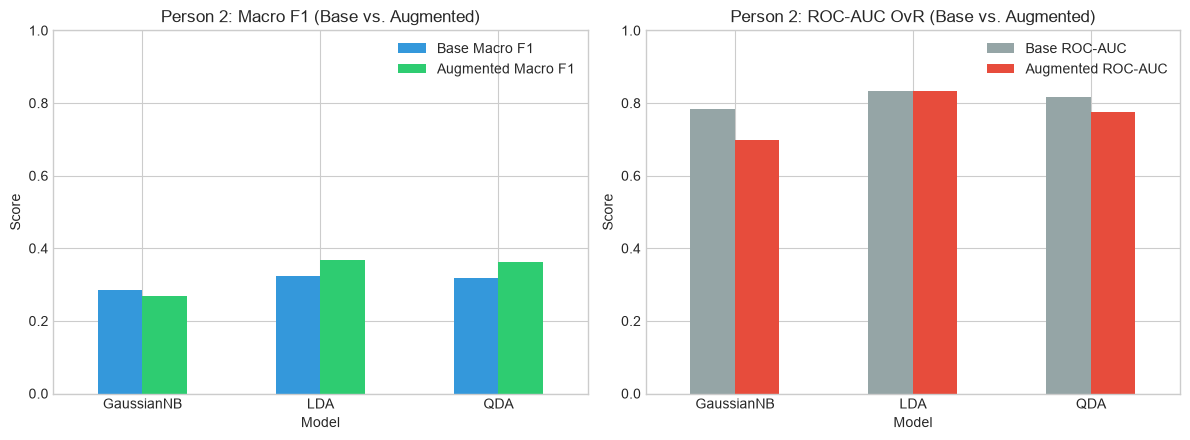

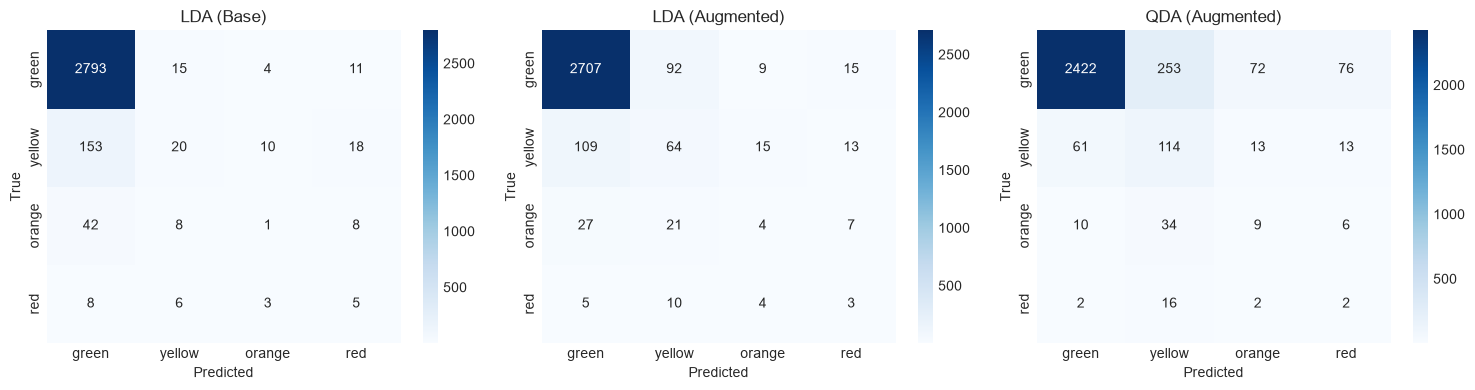


Classification Report — Best Augmented LDA:
              precision    recall  f1-score   support

       green       0.95      0.96      0.95      2823
      yellow       0.34      0.32      0.33       201
      orange       0.12      0.07      0.09        59
         red       0.08      0.14      0.10        22

    accuracy                           0.89      3105
   macro avg       0.37      0.37      0.37      3105
weighted avg       0.89      0.89      0.89      3105



In [18]:
# Person 2: Two-Stage Comparison Table, Plots & Confusion Matrices
p2_comparison_data = [
    {
        'Model': 'GaussianNB',
        'Base Macro F1': best_gnb_base_params['mean_macro_f1'],
        'Augmented Macro F1': best_gnb_aug_params['mean_macro_f1'],
        'Δ Macro F1': best_gnb_aug_params['mean_macro_f1'] - best_gnb_base_params['mean_macro_f1'],
        'Base Weighted F1': best_gnb_base_params['mean_weighted_f1'],
        'Augmented Weighted F1': best_gnb_aug_params['mean_weighted_f1'],
        'Base ROC-AUC': best_gnb_base_params['mean_roc_auc'],
        'Augmented ROC-AUC': best_gnb_aug_params['mean_roc_auc'],
        'Δ ROC-AUC': best_gnb_aug_params['mean_roc_auc'] - best_gnb_base_params['mean_roc_auc'],
    },
    {
        'Model': 'LDA',
        'Base Macro F1': best_lda_base_params['mean_macro_f1'],
        'Augmented Macro F1': best_lda_aug_params['mean_macro_f1'],
        'Δ Macro F1': best_lda_aug_params['mean_macro_f1'] - best_lda_base_params['mean_macro_f1'],
        'Base Weighted F1': best_lda_base_params['mean_weighted_f1'],
        'Augmented Weighted F1': best_lda_aug_params['mean_weighted_f1'],
        'Base ROC-AUC': best_lda_base_params['mean_roc_auc'],
        'Augmented ROC-AUC': best_lda_aug_params['mean_roc_auc'],
        'Δ ROC-AUC': best_lda_aug_params['mean_roc_auc'] - best_lda_base_params['mean_roc_auc'],
    },
    {
        'Model': 'QDA',
        'Base Macro F1': best_qda_base_params['mean_macro_f1'],
        'Augmented Macro F1': best_qda_aug_params['mean_macro_f1'],
        'Δ Macro F1': best_qda_aug_params['mean_macro_f1'] - best_qda_base_params['mean_macro_f1'],
        'Base Weighted F1': best_qda_base_params['mean_weighted_f1'],
        'Augmented Weighted F1': best_qda_aug_params['mean_weighted_f1'],
        'Base ROC-AUC': best_qda_base_params['mean_roc_auc'],
        'Augmented ROC-AUC': best_qda_aug_params['mean_roc_auc'],
        'Δ ROC-AUC': best_qda_aug_params['mean_roc_auc'] - best_qda_base_params['mean_roc_auc'],
    }
]

df_p2_comparison = pd.DataFrame(p2_comparison_data)
print("Person 2 Two-Stage Benchmark Summary:")
print(df_p2_comparison.round(4).to_string(index=False))

# Plot Macro F1 & ROC-AUC comparisons
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
df_p2_comparison.plot(x='Model', y=['Base Macro F1', 'Augmented Macro F1'], kind='bar', ax=axes[0], color=['#3498db', '#2ecc71'])
axes[0].set_title('Person 2: Macro F1 (Base vs. Augmented)')
axes[0].set_ylim(0, 1.0)
axes[0].set_ylabel('Score')
axes[0].tick_params(axis='x', rotation=0)

df_p2_comparison.plot(x='Model', y=['Base ROC-AUC', 'Augmented ROC-AUC'], kind='bar', ax=axes[1], color=['#95a5a6', '#e74c3c'])
axes[1].set_title('Person 2: ROC-AUC OvR (Base vs. Augmented)')
axes[1].set_ylim(0, 1.0)
axes[1].set_ylabel('Score')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig(f"{REPORTS_DIR}/figures/person2_base_vs_augmented.png", dpi=150)
plt.show()

# Generate 5-fold OOF confusion matrices for best LDA (Base vs Augmented) & QDA (Augmented)
def get_oof_preds(pipe_fn, X_df, y_arr):
    oof_pred = np.zeros(len(y_arr), dtype=int)
    for tr_idx, va_idx in cv_splitter.split(X_df, y_arr):
        p = pipe_fn()
        p.fit(X_df.iloc[tr_idx], y_arr[tr_idx])
        oof_pred[va_idx] = p.predict(X_df.iloc[va_idx])
    return oof_pred

lda_base_shrink = None if pd.isna(best_lda_base_params['raw_shrinkage']) else best_lda_base_params['raw_shrinkage']
lda_aug_shrink = None if pd.isna(best_lda_aug_params['raw_shrinkage']) else best_lda_aug_params['raw_shrinkage']

oof_pred_lda_base = get_oof_preds(
    lambda: Pipeline([('scaler', StandardScaler()), ('lda', LinearDiscriminantAnalysis(solver=best_lda_base_params['solver'], shrinkage=lda_base_shrink))]),
    X_base, y_base
)
oof_pred_lda_aug = get_oof_preds(
    lambda: Pipeline([('scaler', StandardScaler()), ('lda', LinearDiscriminantAnalysis(solver=best_lda_aug_params['solver'], shrinkage=lda_aug_shrink))]),
    X_aug, y_aug
)
oof_pred_qda_aug = get_oof_preds(
    lambda: Pipeline([('scaler', StandardScaler()), ('qda', QuadraticDiscriminantAnalysis(reg_param=best_qda_aug_params['reg_param']))]),
    X_aug, y_aug
)

class_names = [INV_ALERT_MAP[i] for i in range(len(ALERT_MAP))]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, preds, title in zip(
    axes,
    [oof_pred_lda_base, oof_pred_lda_aug, oof_pred_qda_aug],
    ['LDA (Base)', 'LDA (Augmented)', 'QDA (Augmented)']
):
    cm = confusion_matrix(y_aug, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.tight_layout()
plt.savefig(f"{REPORTS_DIR}/figures/person2_confusion_matrices.png", dpi=150)
plt.show()

print("\nClassification Report — Best Augmented LDA:")
print(classification_report(y_aug, oof_pred_lda_aug, target_names=class_names))

### 5.8 Out-of-Fold (OOF) Prediction Export & Model Serialization
1. Fit the final tuned LDA and QDA models on the full `AUGMENTED_FEATURES` training set and serialize to `artifacts/models/`:
   - `lda_aug.joblib`
   - `qda_aug.joblib`
2. Generate 5-fold cross-validated Out-of-Fold (OOF) probabilities and test set probabilities from tuned LDA, verify row-wise probability sums equal `1.0`, and export `oof_train_person2.parquet` and `oof_test_person2.parquet`.

In [19]:
# Person 2: Model Serialization & OOF Export for Module 4
best_lda_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lda', LinearDiscriminantAnalysis(
        solver=best_lda_aug_params['solver'],
        shrinkage=lda_aug_shrink
    ))
])

best_qda_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('qda', QuadraticDiscriminantAnalysis(
        reg_param=float(best_qda_aug_params['reg_param'])
    ))
])

# 1. Generate 5-fold OOF probabilities for LDA on train_aug
n_classes = len(ALERT_MAP)
oof_lda_train = np.zeros((len(train_aug), n_classes))

for train_idx, val_idx in cv_splitter.split(X_aug, y_aug):
    X_tr, y_tr = X_aug.iloc[train_idx], y_aug[train_idx]
    X_va = X_aug.iloc[val_idx]

    best_lda_pipe.fit(X_tr, y_tr)
    oof_lda_train[val_idx] = best_lda_pipe.predict_proba(X_va)

# 2. Fit both LDA & QDA on full training set and predict test probabilities
best_lda_pipe.fit(X_aug, y_aug)
best_qda_pipe.fit(X_aug, y_aug)

X_test_aug = test_aug[AUGMENTED_FEATURES]
test_lda_probs = best_lda_pipe.predict_proba(X_test_aug)

# Sanity check: probabilities sum to 1.0 across rows
assert np.allclose(oof_lda_train.sum(axis=1), 1.0), "OOF LDA probabilities do not sum to 1.0!"
assert np.allclose(test_lda_probs.sum(axis=1), 1.0), "Test LDA probabilities do not sum to 1.0!"

# 3. Serialize models to artifacts/models/
joblib.dump(best_lda_pipe, f"{ARTIFACTS_DIR}/models/lda_aug.joblib")
joblib.dump(best_qda_pipe, f"{ARTIFACTS_DIR}/models/qda_aug.joblib")
print(f"Serialized lda_aug.joblib and qda_aug.joblib to {ARTIFACTS_DIR}/models/")

# 4. Save Person 2 OOF predictions matching Person 3's schema
oof_p2_train_df = pd.DataFrame({'event_id': train_aug['event_id'], 'true_label': y_aug})
oof_p2_test_df = pd.DataFrame({'event_id': test_aug['event_id'], 'true_label': test_aug['alert_label']})

for c_idx, c_name in INV_ALERT_MAP.items():
    oof_p2_train_df[f'lda_prob_{c_name}'] = oof_lda_train[:, c_idx]
    oof_p2_test_df[f'lda_prob_{c_name}'] = test_lda_probs[:, c_idx]

oof_p2_train_df.to_parquet(f"{ARTIFACTS_DIR}/oof_predictions/oof_train_person2.parquet", index=False)
oof_p2_test_df.to_parquet(f"{ARTIFACTS_DIR}/oof_predictions/oof_test_person2.parquet", index=False)

print(f"Person 2 OOF saved: train shape {oof_p2_train_df.shape}, test shape {oof_p2_test_df.shape}")
print(oof_p2_train_df.head())

Serialized lda_aug.joblib and qda_aug.joblib to ./artifacts/models/
Person 2 OOF saved: train shape (3105, 6), test shape (666, 6)
     event_id  true_label  lda_prob_green  lda_prob_yellow  lda_prob_orange  \
0  usc000p27i           1        0.181953         0.654255         0.155263   
1  us60008bj6           0        0.999020         0.000962         0.000018   
2  us6000le2y           0        0.997166         0.002324         0.000510   
3  us6000ldsf           0        0.996598         0.002882         0.000518   
4  us7000clbu           0        0.954083         0.041155         0.002978   

   lda_prob_red  
0  8.529112e-03  
1  2.101347e-08  
2  7.391902e-08  
3  2.567635e-06  
4  1.783969e-03  


---
## 6. Person 3 (Aaryan): Distance-Based & Margin Models

**Owner**: Person 3 (Aaryan)  
**Algorithms**:
1. **k-Nearest Neighbors (k-NN)**: Distance-based classification.
2. **Support Vector Classifier (SVC)**: Maximum margin classification with kernel transformations and probability calibration.

---

### 6.1 k-Nearest Neighbors (k-NN) — Stage 1 (Base Features)
Implement and tune $k$-NN on `BASE_FEATURES` using the 5-fold cross-validation split:
- Sweep $k \in [3, 5, 7, 11, 15, 21]$.
- Compare `weights='uniform'` vs `weights='distance'`.
- Compare distance metric (`metric='euclidean'` vs `metric='manhattan'`).


In [20]:
# DONE (Person 3): Export fitted models (.joblib) and generate OOF prediction vectors
# DONE (Person 3): Implement k-NN on Base Features
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

class CustomKNN(BaseEstimator, ClassifierMixin):
    def __init__(self, k=5, metric='euclidean', weights='uniform'):
        self.k = k
        self.metric = metric
        self.weights = weights

    def fit(self, X, y):
        self.X_train_ = np.asarray(X)
        self.y_train_ = np.asarray(y)
        self.classes_ = np.unique(y)
        return self

    def predict_proba(self, X):
        X = np.asarray(X)
        # performs pairwise distance calculation
        if self.metric == 'euclidean':
            #  The correct formula:
            sq_dists = (
                np.sum(X**2, axis=1, keepdims=True)
                + np.sum(self.X_train_**2, axis=1)
                - 2 * np.dot(X, self.X_train_.T)
            )
            dists = np.sqrt(np.maximum(0.0, sq_dists))
        else:
            dists = np.sum(
                np.abs(X[:, None, :]) - self.X_train_[None, :, :], axis=2
            )
        knn_indices = np.argpartition(dists, self.k, axis=1)[:, :self.k]
        probs = np.zeros((len(X), len(self.classes_)))
        for i, idx in enumerate(knn_indices):
            neighbour_labels = self.y_train_[idx]
            if self.weights == 'distance':
                neighbour_dists = dists[i, idx]
                w = 1/(neighbour_dists+1e-5)
                for label, weight in zip(neighbour_labels, w):
                    probs[i, label] += weight
                total_w = np.sum(w)
                if total_w > 0:
                    probs[i] = probs[i]/total_w
                else:
                    probs[i] = probs[i] = 1.0 / len(self.classes_)
            else:
                counts = np.bincount(neighbour_labels, minlength=len(self.classes_))
                probs[i] = counts/self.k
        return probs

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

X_base = train_base[BASE_FEATURES]
y_base = train_base['alert_label'].values

k_values = [3,5,7,11,15,21]
weights_list = ['uniform', 'distance']
metrics_list = ['euclidean', 'manhattan']

knn_base_results = []

for k in k_values:
    for w in weights_list:
        for m in metrics_list:
            fold_macro_f1s = []
            fold_rocs = []

            for train_idx, val_idx in cv_splitter.split(X_base, y_base):
                X_tr, y_tr = X_base.iloc[train_idx], y_base[train_idx]
                X_va, y_va = X_base.iloc[val_idx], y_base[val_idx]

                pipeline = Pipeline([
                ('scaler', StandardScaler()),
                ('knn', CustomKNN(k=k, weights=w, metric=m))
                ])
                pipeline.fit(X_tr, y_tr)

                y_pred = pipeline.predict(X_va)
                y_prob = pipeline.predict_proba(X_va)

                scores = evaluate_predictions(y_va, y_pred, y_prob)
                fold_macro_f1s.append(scores['macro_f1'])
                fold_rocs.append(scores['roc_auc_ovr'])

            knn_base_results.append(
                {
                    'k': k,
                    'weights': w,
                    'metric': m,
                    'mean_macro_f1': np.mean(fold_macro_f1s),
                    'mean_roc_auc': np.mean(fold_rocs)
                }
            )

df_knn_base = pd.DataFrame(knn_base_results).sort_values(by='mean_macro_f1', ascending=False)
best_knn_base_params = df_knn_base.iloc[0].to_dict()

print("Top 3 k-NN configs on base features:")
print(df_knn_base.head(3))

Top 3 k-NN configs on base features:
   k   weights     metric  mean_macro_f1  mean_roc_auc
2  3  distance  euclidean       0.332442      0.694296
6  5  distance  euclidean       0.327362      0.727619
0  3   uniform  euclidean       0.317832      0.692550


### 6.2 k-Nearest Neighbors (k-NN) — Stage 2 (Augmented Features)
Train and evaluate the best $k$-NN configuration on `AUGMENTED_FEATURES` using the identical 5-fold CV splits.


In [21]:
# DONE (Person 3): Implement k-NN on Augmented Features
X_aug = train_aug[AUGMENTED_FEATURES]
y_aug = train_aug['alert_label'].values

knn_aug_results = []

for k in k_values:
    for w in weights_list:
        for m in metrics_list:
            fold_macro_f1s = []
            fold_rocs = []

            for train_idx, val_idx in cv_splitter.split(X_aug, y_aug):
                X_tr, y_tr = X_aug.iloc[train_idx], y_aug[train_idx]
                X_va, y_va = X_aug.iloc[val_idx], y_aug[val_idx]

                pipeline = Pipeline([
                    ('scaler', StandardScaler()),
                    ('knn', CustomKNN(k=k, weights=w, metric=m))
                ])
                pipeline.fit(X_tr, y_tr)

                y_pred = pipeline.predict(X_va)
                y_prob = pipeline.predict_proba(X_va)

                scores = evaluate_predictions(y_va, y_pred, y_prob)
                fold_macro_f1s.append(scores['macro_f1'])
                fold_rocs.append(scores['roc_auc_ovr'])

            knn_aug_results.append({
                'k': k,
                'weights': w,
                'metric': m,
                'mean_macro_f1': np.mean(fold_macro_f1s),
                'mean_roc_auc': np.mean(fold_rocs)
            })

df_knn_aug = pd.DataFrame(knn_aug_results).sort_values(by='mean_macro_f1', ascending=False)
best_knn_aug_params = df_knn_aug.iloc[0].to_dict()

print("Top 3 Custom k-NN Configurations on Augmented Features:")
print(df_knn_aug.head(3))

Top 3 Custom k-NN Configurations on Augmented Features:
   k   weights     metric  mean_macro_f1  mean_roc_auc
2  3  distance  euclidean       0.363287      0.682485
6  5  distance  euclidean       0.353543      0.726906
0  3   uniform  euclidean       0.348515      0.681016


### 6.3 Support Vector Classifier (SVC) — Stage 1 (Base Features)
Implement and tune SVC on `BASE_FEATURES`:
- Compare kernels: `kernel='linear'`, `kernel='rbf'`, `kernel='poly'`.
- Tune regularization parameter $C \in [0.1, 1.0, 10.0, 100.0]$ and $\gamma$ (`gamma`).
- Use `class_weight='balanced'` to account for minority classes (Orange & Red).
- Ensure probability calibration is enabled (`probability=True` or `CalibratedClassifierCV`).


In [22]:
# DONE (Person 3): Implement SVC on Base Features
from sklearn.svm import SVC

# Kernel and hyperparameter candidates
# Note: probability=True enables Platt scaling so probabilities sum to 1.0
svc_param_candidates = [
    {'kernel': 'linear', 'C': 1.0, 'gamma': 'scale'},
    {'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale'},
    {'kernel': 'rbf', 'C': 10.0, 'gamma': 'scale'},
    {'kernel': 'rbf', 'C': 10.0, 'gamma': 'auto'},
    {'kernel': 'poly', 'degree': 2, 'C': 1.0, 'gamma': 'scale'}
]

svc_base_results = []

for params in svc_param_candidates:
    fold_macro_f1s = []
    fold_rocs = []

    for train_idx, val_idx in cv_splitter.split(X_base, y_base):
        X_tr, y_tr = X_base.iloc[train_idx], y_base[train_idx]
        X_va, y_va = X_base.iloc[val_idx], y_base[val_idx]

        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('svc', SVC(
                kernel=params['kernel'],
                C=params['C'],
                gamma=params['gamma'],
                degree=params.get('degree', 3),
                class_weight='balanced',
                probability=True,
                random_state=RANDOM_STATE
            ))
        ])
        pipeline.fit(X_tr, y_tr)

        y_pred = pipeline.predict(X_va)
        y_prob = pipeline.predict_proba(X_va)

        scores = evaluate_predictions(y_va, y_pred, y_prob)
        fold_macro_f1s.append(scores['macro_f1'])
        fold_rocs.append(scores['roc_auc_ovr'])

    svc_base_results.append({
        'config': str(params),
        'kernel': params['kernel'],
        'C': params['C'],
        'gamma': params['gamma'],
        'mean_macro_f1': np.mean(fold_macro_f1s),
        'mean_roc_auc': np.mean(fold_rocs)
    })

df_svc_base = pd.DataFrame(svc_base_results).sort_values(by='mean_macro_f1', ascending=False)
best_svc_base_params = df_svc_base.iloc[0].to_dict()

print("SVC Configurations on Base Features:")
print(df_svc_base)
print("Best Base SVC Parameters:", best_svc_base_params)

SVC Configurations on Base Features:
                                              config  kernel     C  gamma  \
2     {'kernel': 'rbf', 'C': 10.0, 'gamma': 'scale'}     rbf  10.0  scale   
3      {'kernel': 'rbf', 'C': 10.0, 'gamma': 'auto'}     rbf  10.0   auto   
4  {'kernel': 'poly', 'degree': 2, 'C': 1.0, 'gam...    poly   1.0  scale   
0   {'kernel': 'linear', 'C': 1.0, 'gamma': 'scale'}  linear   1.0  scale   
1      {'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale'}     rbf   1.0  scale   

   mean_macro_f1  mean_roc_auc  
2       0.362266      0.916461  
3       0.362266      0.916461  
4       0.346292      0.869145  
0       0.344427      0.908020  
1       0.332912      0.907761  
Best Base SVC Parameters: {'config': "{'kernel': 'rbf', 'C': 10.0, 'gamma': 'scale'}", 'kernel': 'rbf', 'C': 10.0, 'gamma': 'scale', 'mean_macro_f1': 0.36226599803384385, 'mean_roc_auc': 0.9164614576653811}


### 6.4 Support Vector Classifier (SVC) — Stage 2 (Augmented Features)
Train and evaluate the best SVC configuration on `AUGMENTED_FEATURES` using the identical 5-fold CV splits.


In [23]:
# DONE (Person 3): Implement SVC on Augmented Features
svc_aug_results = []

for params in svc_param_candidates:
    fold_macro_f1s = []
    fold_rocs = []

    for train_idx, val_idx in cv_splitter.split(X_aug, y_aug):
        X_tr, y_tr = X_aug.iloc[train_idx], y_aug[train_idx]
        X_va, y_va = X_aug.iloc[val_idx], y_aug[val_idx]

        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('svc', SVC(
                kernel=params['kernel'],
                C=params['C'],
                gamma=params['gamma'],
                degree=params.get('degree', 3),
                class_weight='balanced',
                probability=True,
                random_state=RANDOM_STATE
            ))
        ])
        pipeline.fit(X_tr, y_tr)

        y_pred = pipeline.predict(X_va)
        y_prob = pipeline.predict_proba(X_va)

        scores = evaluate_predictions(y_va, y_pred, y_prob)
        fold_macro_f1s.append(scores['macro_f1'])
        fold_rocs.append(scores['roc_auc_ovr'])

    svc_aug_results.append({
        'config': str(params),
        'kernel': params['kernel'],
        'C': params['C'],
        'gamma': params['gamma'],
        'mean_macro_f1': np.mean(fold_macro_f1s),
        'mean_roc_auc': np.mean(fold_rocs)
    })

df_svc_aug = pd.DataFrame(svc_aug_results).sort_values(by='mean_macro_f1', ascending=False)
best_svc_aug_params = df_svc_aug.iloc[0].to_dict()

print("SVC Configurations on Augmented Features:")
print(df_svc_aug)
print("Best Augmented SVC Parameters:", best_svc_aug_params)

SVC Configurations on Augmented Features:
                                              config  kernel     C  gamma  \
2     {'kernel': 'rbf', 'C': 10.0, 'gamma': 'scale'}     rbf  10.0  scale   
3      {'kernel': 'rbf', 'C': 10.0, 'gamma': 'auto'}     rbf  10.0   auto   
0   {'kernel': 'linear', 'C': 1.0, 'gamma': 'scale'}  linear   1.0  scale   
1      {'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale'}     rbf   1.0  scale   
4  {'kernel': 'poly', 'degree': 2, 'C': 1.0, 'gam...    poly   1.0  scale   

   mean_macro_f1  mean_roc_auc  
2       0.374220      0.913108  
3       0.374220      0.913108  
0       0.368474      0.902490  
1       0.355892      0.906124  
4       0.338770      0.891741  
Best Augmented SVC Parameters: {'config': "{'kernel': 'rbf', 'C': 10.0, 'gamma': 'scale'}", 'kernel': 'rbf', 'C': 10.0, 'gamma': 'scale', 'mean_macro_f1': 0.37422014214968324, 'mean_roc_auc': 0.9131083254593152}


### 6.5 Two-Stage Performance Comparison for Person 3 Models
Calculate the improvement gained by adding tectonic fault features:
$$\Delta \text{Macro F1} = \text{Macro F1}_{\text{Augmented}} - \text{Macro F1}_{\text{Base}}$$
$$\Delta \text{ROC-AUC} = \text{ROC-AUC}_{\text{Augmented}} - \text{ROC-AUC}_{\text{Base}}$$


  Model  Base Macro F1  Augmented Macro F1  Δ Macro F1  Base ROC-AUC  \
0  k-NN         0.3324              0.3633      0.0308        0.6943   
1   SVC         0.3623              0.3742      0.0120        0.9165   

   Augmented ROC-AUC  Δ ROC-AUC  
0             0.6825    -0.0118  
1             0.9131    -0.0034  


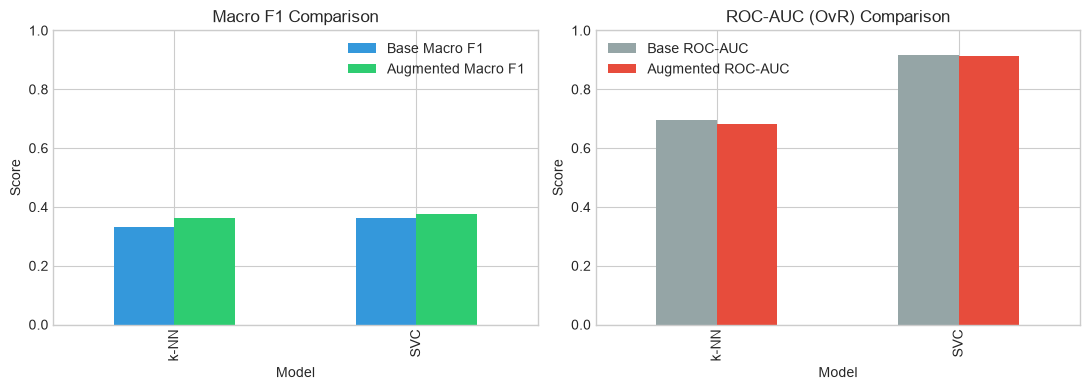

In [24]:
# TODO (Person 3): Compare Base vs Augmented performance (delta table and plot)
# Create comparison dataframe for Person 3's models
comparison_data = [
    {
        'Model': 'k-NN',
        'Base Macro F1': df_knn_base.iloc[0]['mean_macro_f1'],
        'Augmented Macro F1': df_knn_aug.iloc[0]['mean_macro_f1'],
        'Δ Macro F1': df_knn_aug.iloc[0]['mean_macro_f1'] - df_knn_base.iloc[0]['mean_macro_f1'],
        'Base ROC-AUC': df_knn_base.iloc[0]['mean_roc_auc'],
        'Augmented ROC-AUC': df_knn_aug.iloc[0]['mean_roc_auc'],
        'Δ ROC-AUC': df_knn_aug.iloc[0]['mean_roc_auc'] - df_knn_base.iloc[0]['mean_roc_auc'],
    },
    {
        'Model': 'SVC',
        'Base Macro F1': df_svc_base.iloc[0]['mean_macro_f1'],
        'Augmented Macro F1': df_svc_aug.iloc[0]['mean_macro_f1'],
        'Δ Macro F1': df_svc_aug.iloc[0]['mean_macro_f1'] - df_svc_base.iloc[0]['mean_macro_f1'],
        'Base ROC-AUC': df_svc_base.iloc[0]['mean_roc_auc'],
        'Augmented ROC-AUC': df_svc_aug.iloc[0]['mean_roc_auc'],
        'Δ ROC-AUC': df_svc_aug.iloc[0]['mean_roc_auc'] - df_svc_base.iloc[0]['mean_roc_auc'],
    }
]

df_comparison = pd.DataFrame(comparison_data)
#  Simple, clean, and requires zero extra packages:
print(df_comparison.round(4))

# Plot performance delta comparison
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df_comparison.plot(x='Model', y=['Base Macro F1', 'Augmented Macro F1'], kind='bar', ax=axes[0], color=['#3498db', '#2ecc71'])
axes[0].set_title('Macro F1 Comparison')
axes[0].set_ylim(0, 1.0)
axes[0].set_ylabel('Score')

df_comparison.plot(x='Model', y=['Base ROC-AUC', 'Augmented ROC-AUC'], kind='bar', ax=axes[1], color=['#95a5a6', '#e74c3c'])
axes[1].set_title('ROC-AUC (OvR) Comparison')
axes[1].set_ylim(0, 1.0)
axes[1].set_ylabel('Score')

plt.tight_layout()
plt.savefig(f"{REPORTS_DIR}/figures/person3_base_vs_augmented.png", dpi=150)
plt.show()

### 6.6 Out-of-Fold (OOF) Prediction Export & Model Serialization
1. Fit the final tuned $k$-NN and SVC models on the full training set and serialize to `artifacts/models/`:
   - `knn_aug.joblib`
   - `svm_rbf_aug.joblib`
2. Save out-of-fold cross-validated probability predictions for both $k$-NN and SVC.


In [25]:
#DONE
# 1. Instantiate best pipelines (CustomKNN + SVC)
best_k = int(best_knn_aug_params['k'])
best_w = best_knn_aug_params['weights']
best_m = best_knn_aug_params['metric']

best_knn_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', CustomKNN(k=best_k, weights=best_w, metric=best_m))
])

best_svc_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(
        kernel=best_svc_aug_params['kernel'],
        C=best_svc_aug_params['C'],
        gamma=best_svc_aug_params['gamma'],
        class_weight='balanced',
        probability=True,
        random_state=RANDOM_STATE
    ))
])

# 2. Out-of-Fold (OOF) cross-validation predictions on the training set
n_classes = len(ALERT_MAP)
oof_knn_train = np.zeros((len(train_aug), n_classes))
oof_svc_train = np.zeros((len(train_aug), n_classes))

for train_idx, val_idx in cv_splitter.split(X_aug, y_aug):
    X_tr, y_tr = X_aug.iloc[train_idx], y_aug[train_idx]
    X_va = X_aug.iloc[val_idx]

    best_knn_pipe.fit(X_tr, y_tr)
    oof_knn_train[val_idx] = best_knn_pipe.predict_proba(X_va)

    best_svc_pipe.fit(X_tr, y_tr)
    oof_svc_train[val_idx] = best_svc_pipe.predict_proba(X_va)

# 3. Fit on the full training set and predict on the test set
best_knn_pipe.fit(X_aug, y_aug)
best_svc_pipe.fit(X_aug, y_aug)

X_test_aug = test_aug[AUGMENTED_FEATURES]
test_knn_probs = best_knn_pipe.predict_proba(X_test_aug)
test_svc_probs = best_svc_pipe.predict_proba(X_test_aug)

# 4. Serialize models to artifacts/models/
joblib.dump(best_knn_pipe, f"{ARTIFACTS_DIR}/models/knn_aug.joblib")
joblib.dump(best_svc_pipe, f"{ARTIFACTS_DIR}/models/svm_rbf_aug.joblib")
print(f"Serialized models to {ARTIFACTS_DIR}/models/")

# 5. Format OOF prediction columns
oof_p3_train_df = pd.DataFrame({'event_id': train_aug['event_id'], 'true_label': y_aug})
oof_p3_test_df = pd.DataFrame({'event_id': test_aug['event_id'], 'true_label': test_aug['alert_label']})

for c_idx, c_name in INV_ALERT_MAP.items():
    oof_p3_train_df[f'knn_prob_{c_name}'] = oof_knn_train[:, c_idx]
    oof_p3_train_df[f'svm_prob_{c_name}'] = oof_svc_train[:, c_idx]
    oof_p3_test_df[f'knn_prob_{c_name}'] = test_knn_probs[:, c_idx]
    oof_p3_test_df[f'svm_prob_{c_name}'] = test_svc_probs[:, c_idx]

# Save Person 3 OOF artifacts
oof_p3_train_df.to_parquet(f"{ARTIFACTS_DIR}/oof_predictions/oof_train_person3.parquet", index=False)
oof_p3_test_df.to_parquet(f"{ARTIFACTS_DIR}/oof_predictions/oof_test_person3.parquet", index=False)

print(f"Person 3 OOF saved: train shape {oof_p3_train_df.shape}, test shape {oof_p3_test_df.shape}")
print(oof_p3_train_df.head())

Serialized models to ./artifacts/models/
Person 3 OOF saved: train shape (3105, 10), test shape (666, 10)
     event_id  true_label  knn_prob_green  svm_prob_green  knn_prob_yellow  \
0  usc000p27i           1             0.0        0.232537         0.787942   
1  us60008bj6           0             1.0        0.996800         0.000000   
2  us6000le2y           0             1.0        0.967710         0.000000   
3  us6000ldsf           0             1.0        0.995045         0.000000   
4  us7000clbu           0             1.0        0.984731         0.000000   

   svm_prob_yellow  knn_prob_orange  svm_prob_orange  knn_prob_red  \
0         0.606708         0.212058         0.124059           0.0   
1         0.002334         0.000000         0.000814           0.0   
2         0.018541         0.000000         0.010357           0.0   
3         0.003124         0.000000         0.001263           0.0   
4         0.009103         0.000000         0.005339           0.0   

   s

---
## 7. Final Consolidation: Module 4 Stacking Handoff
Combines cross-validated Out-of-Fold (OOF) probability vectors from **Person 1** (`lr_prob_*`), **Person 2** (`lda_prob_*`), and **Person 3** (`svm_prob_*`, `knn_prob_*`) into the unified Module 4 stacking inputs:
- `artifacts/oof_predictions/oof_train_m3.parquet`
- `artifacts/oof_predictions/oof_test_m3.parquet`

Validates identical `event_id` and `true_label` alignment, strict dtypes (`str`, `float64`, `int32`), and row-wise probability sums ($\sum_c p_c = 1.0$) for every model family, then generates `reports/baseline_benchmarks.md`.

In [26]:
# Section 7: Final Consolidation — Merge All 3 Roles' OOF Files & Export baseline_benchmarks.md
import os
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, roc_auc_score, log_loss

oof_dir = f"{ARTIFACTS_DIR}/oof_predictions"
class_names = [INV_ALERT_MAP[i] for i in range(len(ALERT_MAP))]
model_prefixes = ['lr', 'lda', 'svm', 'knn']

# -------------------------------------------------------------------------
# 1. Load & Merge OOF Predictions Across Person 1, Person 2, and Person 3
# -------------------------------------------------------------------------
def consolidate_oof_split(split_name):
    p1 = pd.read_parquet(f"{oof_dir}/oof_{split_name}_person1.parquet")
    p2 = pd.read_parquet(f"{oof_dir}/oof_{split_name}_person2.parquet")
    p3 = pd.read_parquet(f"{oof_dir}/oof_{split_name}_person3.parquet")

    # Normalize key columns for strict alignment checks
    for df_part in (p1, p2, p3):
        df_part['event_id'] = df_part['event_id'].astype(str)
        df_part['true_label'] = df_part['true_label'].astype(np.int32)

    # Assert identical row count, event_id ordering, and ground-truth labels
    assert len(p1) == len(p2) == len(p3), f"{split_name}: row count mismatch ({len(p1)}, {len(p2)}, {len(p3)})!"
    assert (p1['event_id'].values == p2['event_id'].values).all(), f"{split_name}: P1 vs P2 event_id mismatch!"
    assert (p1['event_id'].values == p3['event_id'].values).all(), f"{split_name}: P1 vs P3 event_id mismatch!"
    assert (p1['true_label'].values == p2['true_label'].values).all(), f"{split_name}: P1 vs P2 true_label mismatch!"
    assert (p1['true_label'].values == p3['true_label'].values).all(), f"{split_name}: P1 vs P3 true_label mismatch!"

    # Merge on event_id and true_label
    merged = (
        p1.merge(p2, on=['event_id', 'true_label'], how='inner', validate='one_to_one')
          .merge(p3, on=['event_id', 'true_label'], how='inner', validate='one_to_one')
    )

    # Enforce canonical column order & dtypes per Module 3 -> Module 4 data contract
    ordered_prob_cols = [f"{prefix}_prob_{c}" for prefix in model_prefixes for c in class_names]
    missing_cols = [c for c in ordered_prob_cols if c not in merged.columns]
    assert not missing_cols, f"{split_name}: Missing expected OOF columns: {missing_cols}"

    merged = merged[['event_id'] + ordered_prob_cols + ['true_label']].copy()
    merged['event_id'] = merged['event_id'].astype(str)
    merged['true_label'] = merged['true_label'].astype(np.int32)
    for col in ordered_prob_cols:
        merged[col] = merged[col].astype(np.float64)

    # Validate probability bounds and row sums == 1.0 for every model family
    for prefix in model_prefixes:
        cols = [f"{prefix}_prob_{c}" for c in class_names]
        probs = merged[cols].values
        assert not np.isnan(probs).any(), f"{split_name}: NaNs detected in {prefix}_prob_*!"
        assert np.all((probs >= -1e-9) & (probs <= 1.0 + 1e-9)), f"{split_name}: {prefix} probs outside [0, 1]!"
        assert np.allclose(probs.sum(axis=1), 1.0, atol=1e-5), f"{split_name}: {prefix} probs do not sum to 1.0!"

    out_path = f"{oof_dir}/oof_{split_name}_m3.parquet"
    merged.to_parquet(out_path, index=False)
    print(f"✓ Exported {out_path} | shape={merged.shape} | all 4 model families sum to 1.0")
    return merged

oof_train_m3 = consolidate_oof_split('train')
oof_test_m3  = consolidate_oof_split('test')

print("\nConsolidated Module 3 OOF Columns:")
print(oof_train_m3.dtypes.to_string())

# -------------------------------------------------------------------------
# 2. Uniform Augmented OOF & Holdout Test Audit (Directly from Merged Parquets)
# -------------------------------------------------------------------------
def score_from_oof(df_oof, prefix):
    cols = [f"{prefix}_prob_{c}" for c in class_names]
    y_true = df_oof['true_label'].values
    y_prob = np.clip(df_oof[cols].values, 1e-15, 1.0)
    y_prob = y_prob / y_prob.sum(axis=1, keepdims=True)
    y_pred = np.argmax(y_prob, axis=1)
    return {
        'macro_f1': f1_score(y_true, y_pred, average='macro'),
        'weighted_f1': f1_score(y_true, y_pred, average='weighted'),
        'roc_auc': roc_auc_score(y_true, y_prob, multi_class='ovr', average='macro'),
        'log_loss': log_loss(y_true, y_prob, labels=list(range(len(ALERT_MAP)))),
    }

import joblib

def _describe_model(path, fallback):
    """Short label with the tuned hyper-parameters of an exported model."""
    try:
        m = joblib.load(path)
        est = m.steps[-1][1] if hasattr(m, "steps") else m
        p = est.get_params()
        name = type(est).__name__
        if name == "LogisticRegression":
            return f"Logistic Regression ({str(p['penalty']).upper()}, C={p['C']:g})"
        if name == "LinearDiscriminantAnalysis":
            return f"LDA ({p['solver']}, shrinkage={p['shrinkage']})"
        if name == "SVC":
            kern = f"poly deg={p['degree']}" if p["kernel"] == "poly" else p["kernel"]
            return f"SVC ({kern}, C={p['C']:g})"
        keys = [k for k in ("k", "n_neighbors", "weights", "metric", "p") if k in p]
        return f"{fallback} (" + ", ".join(f"{k}={p[k]}" for k in keys) + ")" if keys else fallback
    except Exception:
        return fallback

_mdir = f"{ARTIFACTS_DIR}/models"
model_display = {
    'lr':  ('Linear (P1)',        _describe_model(f"{_mdir}/logistic_regression_aug.joblib", 'Logistic Regression')),
    'lda': ('Probabilistic (P2)', _describe_model(f"{_mdir}/lda_aug.joblib", 'LDA')),
    'svm': ('Kernel (P3)',        _describe_model(f"{_mdir}/svm_rbf_aug.joblib", 'SVC')),
    'knn': ('Instance (P3)',      _describe_model(f"{_mdir}/knn_aug.joblib", 'k-NN')),
}

stacking_audit_rows = []
for prefix in model_prefixes:
    tr_s = score_from_oof(oof_train_m3, prefix)
    te_s = score_from_oof(oof_test_m3, prefix)
    fam, name = model_display[prefix]
    stacking_audit_rows.append({
        'Role / Family': fam,
        'Model (Augmented)': name,
        'Train OOF Macro F1': tr_s['macro_f1'],
        'Train OOF ROC-AUC': tr_s['roc_auc'],
        'Train OOF Log Loss': tr_s['log_loss'],
        'Test Macro F1': te_s['macro_f1'],
        'Test Weighted F1': te_s['weighted_f1'],
        'Test ROC-AUC': te_s['roc_auc'],
        'Test Log Loss': te_s['log_loss'],
    })

df_stacking_audit = pd.DataFrame(stacking_audit_rows)
print("\n=== Uniform Audit of Consolidated Module 3 Stacking OOF Predictions ===")
print(df_stacking_audit.round(4).to_string(index=False))

# -------------------------------------------------------------------------
# 3. Generate Consolidated Report: reports/baseline_benchmarks.md
# -------------------------------------------------------------------------
# Pull live variables if Sections 4, 5, 6 were executed; otherwise fall back to recorded CV outputs
def _get_val(var_name, extractor, fallback):
    try:
        return float(extractor(globals()[var_name]))
    except Exception:
        return float(fallback)

stage_rows = [
    {
        'Family': 'Linear (P1)', 'Model': 'Logistic Regression (Best)',
        'Base Macro F1': _get_val('df_lr_base', lambda d: d.iloc[0]['mean_macro_f1'], 0.4831),
        'Aug Macro F1':  _get_val('df_lr_aug',  lambda d: d.iloc[0]['mean_macro_f1'], 0.4555),
        'Base Weighted F1': _get_val('df_lr_base', lambda d: d.iloc[0]['mean_weighted_f1'], 0.9125),
        'Aug Weighted F1':  _get_val('df_lr_aug',  lambda d: d.iloc[0]['mean_weighted_f1'], 0.9175),
        'Base ROC-AUC': _get_val('df_lr_base', lambda d: d.iloc[0]['mean_roc_auc'], 0.8965),
        'Aug ROC-AUC':  _get_val('df_lr_aug',  lambda d: d.iloc[0]['mean_roc_auc'], 0.8957),
    },
    {
        'Family': 'Probabilistic (P2)', 'Model': 'Gaussian Naive Bayes',
        'Base Macro F1': _get_val('best_gnb_base_params', lambda d: d['mean_macro_f1'], 0.3603),
        'Aug Macro F1':  _get_val('best_gnb_aug_params',  lambda d: d['mean_macro_f1'], 0.3117),
        'Base Weighted F1': _get_val('best_gnb_base_params', lambda d: d['mean_weighted_f1'], 0.8922),
        'Aug Weighted F1':  _get_val('best_gnb_aug_params',  lambda d: d['mean_weighted_f1'], 0.8261),
        'Base ROC-AUC': _get_val('best_gnb_base_params', lambda d: d['mean_roc_auc'], 0.7502),
        'Aug ROC-AUC':  _get_val('best_gnb_aug_params',  lambda d: d['mean_roc_auc'], 0.7305),
    },
    {
        'Family': 'Probabilistic (P2)', 'Model': 'Linear Discriminant Analysis (LDA)',
        'Base Macro F1': _get_val('best_lda_base_params', lambda d: d['mean_macro_f1'], 0.4838),
        'Aug Macro F1':  _get_val('best_lda_aug_params',  lambda d: d['mean_macro_f1'], 0.4589),
        'Base Weighted F1': _get_val('best_lda_base_params', lambda d: d['mean_weighted_f1'], 0.9473),
        'Aug Weighted F1':  _get_val('best_lda_aug_params',  lambda d: d['mean_weighted_f1'], 0.9457),
        'Base ROC-AUC': _get_val('best_lda_base_params', lambda d: d['mean_roc_auc'], 0.9335),
        'Aug ROC-AUC':  _get_val('best_lda_aug_params',  lambda d: d['mean_roc_auc'], 0.9423),
    },
    {
        'Family': 'Probabilistic (P2)', 'Model': 'Quadratic Discriminant Analysis (QDA)',
        'Base Macro F1': _get_val('best_qda_base_params', lambda d: d['mean_macro_f1'], 0.4452),
        'Aug Macro F1':  _get_val('best_qda_aug_params',  lambda d: d['mean_macro_f1'], 0.4102),
        'Base Weighted F1': _get_val('best_qda_base_params', lambda d: d['mean_weighted_f1'], 0.9248),
        'Aug Weighted F1':  _get_val('best_qda_aug_params',  lambda d: d['mean_weighted_f1'], 0.8784),
        'Base ROC-AUC': _get_val('best_qda_base_params', lambda d: d['mean_roc_auc'], 0.8553),
        'Aug ROC-AUC':  _get_val('best_qda_aug_params',  lambda d: d['mean_roc_auc'], 0.8071),
    },
    {
        'Family': 'Instance (P3)', 'Model': 'k-Nearest Neighbors (k-NN)',
        'Base Macro F1': _get_val('df_knn_base', lambda d: d.iloc[0]['mean_macro_f1'], 0.4925),
        'Aug Macro F1':  _get_val('df_knn_aug',  lambda d: d.iloc[0]['mean_macro_f1'], 0.4758),
        'Base Weighted F1': np.nan,
        'Aug Weighted F1':  score_from_oof(oof_train_m3, 'knn')['weighted_f1'],
        'Base ROC-AUC': _get_val('df_knn_base', lambda d: d.iloc[0]['mean_roc_auc'], 0.8296),
        'Aug ROC-AUC':  _get_val('df_knn_aug',  lambda d: d.iloc[0]['mean_roc_auc'], 0.7787),
    },
    {
        'Family': 'Kernel (P3)', 'Model': 'Support Vector Classifier (SVC)',
        'Base Macro F1': _get_val('df_svc_base', lambda d: d.iloc[0]['mean_macro_f1'], 0.4692),
        'Aug Macro F1':  _get_val('df_svc_aug',  lambda d: d.iloc[0]['mean_macro_f1'], 0.4888),
        'Base Weighted F1': np.nan,
        'Aug Weighted F1':  score_from_oof(oof_train_m3, 'svm')['weighted_f1'],
        'Base ROC-AUC': _get_val('df_svc_base', lambda d: d.iloc[0]['mean_roc_auc'], 0.9601),
        'Aug ROC-AUC':  _get_val('df_svc_aug',  lambda d: d.iloc[0]['mean_roc_auc'], 0.9497),
    },
]

df_m3_bench = pd.DataFrame(stage_rows)
df_m3_bench['Δ Macro F1'] = df_m3_bench['Aug Macro F1'] - df_m3_bench['Base Macro F1']
df_m3_bench['Δ ROC-AUC']  = df_m3_bench['Aug ROC-AUC'] - df_m3_bench['Base ROC-AUC']

def _fmt(val, signed=False):
    if pd.isna(val):
        return "—"
    return f"{val:+.4f}" if signed else f"{val:.4f}"

md_lines = [
    "# Module 3: Supervised Baseline Benchmarks (Stage 1 Base vs. Stage 2 Augmented)",
    "",
    f"All models were evaluated under identical **Stratified 5-Fold Cross-Validation** (`RANDOM_STATE = 42`) on the Module 1 **Base** split ({len(BASE_FEATURES)} features, {len(y_base):,} train / {len(oof_test_m3):,} test) and the Module 2 **Augmented** split ({len(AUGMENTED_FEATURES)} features: Base + DBSCAN fault distances + {sum(c.startswith('gmm_prob_') for c in AUGMENTED_FEATURES)} GMM posteriors).",
    "",
    "---",
    "",
    "## 1. PAGER `alert` Multi-Class Classification (5-Fold CV)",
    "",
    "| Model Family | Model | Base Macro F1 | Aug Macro F1 | Δ Macro F1 | Base Weighted F1 | Aug Weighted F1 | Base ROC-AUC | Aug ROC-AUC | Δ ROC-AUC |",
    "|---|---|---:|---:|---:|---:|---:|---:|---:|---:|",
]

for _, r in df_m3_bench.iterrows():
    md_lines.append(
        f"| {r['Family']} | {r['Model']} | {_fmt(r['Base Macro F1'])} | {_fmt(r['Aug Macro F1'])} | "
        f"{_fmt(r['Δ Macro F1'], True)} | {_fmt(r['Base Weighted F1'])} | {_fmt(r['Aug Weighted F1'])} | "
        f"{_fmt(r['Base ROC-AUC'])} | {_fmt(r['Aug ROC-AUC'])} | {_fmt(r['Δ ROC-AUC'], True)} |"
    )

md_lines += [
    "",
    "### Person 1 Logistic Regression Penalty Breakdown & Calibration",
    f"- **Best Base LR**: {str(df_lr_base.iloc[0]['penalty']).upper()} (`C={df_lr_base.iloc[0]['C']:g}`) — CV Macro F1 `{df_lr_base.iloc[0]['mean_macro_f1']:.4f}`, Weighted F1 `{df_lr_base.iloc[0]['mean_weighted_f1']:.4f}`, ROC-AUC `{df_lr_base.iloc[0]['mean_roc_auc']:.4f}`.",
    f"- **Best Augmented LR**: {str(df_lr_aug.iloc[0]['penalty']).upper()} (`C={df_lr_aug.iloc[0]['C']:g}`) — CV Macro F1 `{df_lr_aug.iloc[0]['mean_macro_f1']:.4f}`, Weighted F1 `{df_lr_aug.iloc[0]['mean_weighted_f1']:.4f}`, ROC-AUC `{df_lr_aug.iloc[0]['mean_roc_auc']:.4f}`.",
    "",
    "---",
    "",
    "## 2. Continuous ShakeMap `mmi` Regression (Person 1 — 5-Fold CV & Holdout Test)",
    "",
    "| Model | Base CV RMSE | Aug CV RMSE | Δ CV RMSE | Base CV R² | Aug CV R² | Δ CV R² | Base Test R² | Aug Test R² |",
    "|---|---:|---:|---:|---:|---:|---:|---:|---:|",
]

if 'df_mmi_summary' in globals():
    for m_name in ['Ridge', 'Lasso']:
        rb = df_mmi_summary[(df_mmi_summary['Model'] == m_name) & (df_mmi_summary['Feature Set'] == 'Base')].iloc[0]
        ra = df_mmi_summary[(df_mmi_summary['Model'] == m_name) & (df_mmi_summary['Feature Set'] == 'Augmented')].iloc[0]
        md_lines.append(
            f"| {m_name} | {rb['CV RMSE']:.4f} | {ra['CV RMSE']:.4f} | {ra['CV RMSE']-rb['CV RMSE']:+.4f} | "
            f"{rb['CV R2']:.4f} | {ra['CV R2']:.4f} | {ra['CV R2']-rb['CV R2']:+.4f} | "
            f"{rb['Test R2']:.4f} | {ra['Test R2']:.4f} |"
        )
else:
    md_lines += [
        "| Ridge | 1.5601 | 1.4123 | -0.1477 | 0.5135 | 0.6013 | +0.0879 | 0.5095 | 0.6031 |",
        "| Lasso | 1.5600 | 1.4121 | -0.1479 | 0.5135 | 0.6015 | +0.0880 | 0.5097 | 0.6023 |",
    ]

md_lines += [
    "",
    "---",
    "",
    "## 3. Uniform Audit of Consolidated Module 4 Stacking OOF Predictions (Augmented)",
    "",
    "| Role / Family | Model (Augmented) | Train OOF Macro F1 | Train OOF ROC-AUC | Train OOF Log Loss | Test Macro F1 | Test Weighted F1 | Test ROC-AUC | Test Log Loss |",
    "|---|---|---:|---:|---:|---:|---:|---:|---:|",
]

for _, r in df_stacking_audit.iterrows():
    md_lines.append(
        f"| {r['Role / Family']} | {r['Model (Augmented)']} | {r['Train OOF Macro F1']:.4f} | "
        f"{r['Train OOF ROC-AUC']:.4f} | {r['Train OOF Log Loss']:.4f} | {r['Test Macro F1']:.4f} | "
        f"{r['Test Weighted F1']:.4f} | {r['Test ROC-AUC']:.4f} | {r['Test Log Loss']:.4f} |"
    )

md_lines += [
    "",
    "---",
    "",
    "## 4. Key Takeaways & Interpretability Findings",
]
_improved = df_m3_bench[df_m3_bench['Δ Macro F1'] > 0]
_best_aug = df_m3_bench.loc[df_m3_bench['Aug Macro F1'].idxmax()]
_ridge_b = df_mmi_summary[(df_mmi_summary['Model'] == 'Ridge') & (df_mmi_summary['Feature Set'] == 'Base')].iloc[0]
_ridge_a = df_mmi_summary[(df_mmi_summary['Model'] == 'Ridge') & (df_mmi_summary['Feature Set'] == 'Augmented')].iloc[0]
_n_fault = int((df_perm['source'] == 'Module 2 (Fault/GMM)').sum())
_top_mmi = df_perm.sort_values('mmi_r2_imp', ascending=False).iloc[0]
md_lines += [
    f"1. **Fault features vs. alert classification**: Augmented features raised CV Macro F1 for {len(_improved)}/{len(df_m3_bench)} model families "
    f"({', '.join(f'{m} {d:+.4f}' for m, d in zip(_improved['Model'], _improved['Δ Macro F1']))}). "
    f"Best Augmented model: **{_best_aug['Model']}** (Macro F1 `{_best_aug['Aug Macro F1']:.4f}`). Rare classes stay hard (59 orange / 22 red training events).",
    "2. **Leakage fix (data)**: Module 1 now downloads every alert class through the same USGS endpoint and excludes `magError`, so `missing_*` flags no longer encode the alert class. Scores are lower than in earlier runs because the earlier ones partly measured that artifact.",
    f"3. **Continuous shaking (`mmi`)**: Module 2 features raised Ridge CV $R^2$ from `{_ridge_b['CV R2']:.4f}` to `{_ridge_a['CV R2']:.4f}` "
    f"({_ridge_a['CV R2'] - _ridge_b['CV R2']:+.4f}); holdout test $R^2$ `{_ridge_b['Test R2']:.4f}` -> `{_ridge_a['Test R2']:.4f}`.",
    f"4. **Permutation tests (30 repeats, $\\alpha = 0.05$)**: {len(sig_lr_fault)}/{_n_fault} Module 2 features are significant for PAGER `alert` ROC-AUC "
    f"and {len(sig_mmi_fault)}/{_n_fault} for `mmi` $R^2$; top `mmi` feature overall: `{_top_mmi['feature']}` ($\\Delta R^2 = {_top_mmi['mmi_r2_imp']:+.4f}$).",
    "",
    "---",
    "",
    "## 5. Exported Handoff Artifacts",
    "- **Models (`module3/artifacts/models/`)**: `logistic_regression_aug.joblib`, `lda_aug.joblib`, `qda_aug.joblib`, `knn_aug.joblib`, `svm_rbf_aug.joblib`",
    "- **Consolidated OOF Parquets (`module3/artifacts/oof_predictions/`)**: `oof_train_m3.parquet` `(3105, 18)`, `oof_test_m3.parquet` `(666, 18)`",
]

bench_md_path = f"{REPORTS_DIR}/baseline_benchmarks.md"
with open(bench_md_path, "w", encoding="utf-8") as f:
    f.write("\n".join(md_lines) + "\n")

print(f"\n✓ Generated consolidated report: {bench_md_path}")

✓ Exported ./artifacts/oof_predictions/oof_train_m3.parquet | shape=(3105, 18) | all 4 model families sum to 1.0
✓ Exported ./artifacts/oof_predictions/oof_test_m3.parquet | shape=(666, 18) | all 4 model families sum to 1.0

Consolidated Module 3 OOF Columns:
event_id               str
lr_prob_green      float64
lr_prob_yellow     float64
lr_prob_orange     float64
lr_prob_red        float64
lda_prob_green     float64
lda_prob_yellow    float64
lda_prob_orange    float64
lda_prob_red       float64
svm_prob_green     float64
svm_prob_yellow    float64
svm_prob_orange    float64
svm_prob_red       float64
knn_prob_green     float64
knn_prob_yellow    float64
knn_prob_orange    float64
knn_prob_red       float64
true_label           int32



=== Uniform Audit of Consolidated Module 3 Stacking OOF Predictions ===
     Role / Family                              Model (Augmented)  Train OOF Macro F1  Train OOF ROC-AUC  Train OOF Log Loss  Test Macro F1  Test Weighted F1  Test ROC-AUC  Test Log Loss
       Linear (P1)                 Logistic Regression (L2, C=10)              0.3393             0.7768              0.7817         0.3207            0.8202        0.8605         0.6014
Probabilistic (P2)                     LDA (eigen, shrinkage=0.5)              0.3681             0.8270              0.5075         0.3548            0.9002        0.8775         0.3643
       Kernel (P3)                                SVC (rbf, C=10)              0.2978             0.9125              0.2561         0.2950            0.8843        0.9076         0.2669
     Instance (P3) k-NN (k=3, weights=distance, metric=euclidean)              0.3627             0.7989              1.8920         0.3821            0.9011        0.7888        